# Báo cáo Đánh giá Hiệu quả Tăng trưởng Người dùng (UA) & Tối ưu hóa Chi phí Quảng cáo
### theo Mạng lưới và Quốc gia — Notebook phân tích

**Cách dùng**
1. Đặt notebook cùng thư mục với `ads_network_data.csv` và `country_performance_data.csv` (hoặc sửa đường dẫn ở ô cấu hình).
2. Chạy lần lượt từng ô từ trên xuống (Shift + Enter). Mỗi mục tương ứng một phần trong file Word.
3. Mọi kết quả được lưu tự động vào thư mục `outputs/`:
   - `outputs/figures/` — toàn bộ biểu đồ (.png, 200 dpi). `bieu_do_01…07` khớp Biểu đồ 1–7 trong báo cáo; `bieu_do_bs_…` là biểu đồ **bổ sung** để chứng minh các nhận định.
   - `outputs/tables/` — mọi bảng số liệu (.csv) + `tat_ca_bang.xlsx` (mỗi bảng 1 sheet).
   - `outputs/ket_qua_chinh.json` và `outputs/tom_tat_ket_qua.md` — các con số chính.
4. Ô cuối cùng nén toàn bộ thành **`outputs_bao_cao_UA.zip`** — gửi file zip này (hoặc các ảnh + `tom_tat_ket_qua.md`) để điền tiếp vào báo cáo.

| Phần notebook | Phần trong báo cáo |
|---|---|
| 0. Cấu hình | — |
| 2. Hiểu dữ liệu & chỉ số | Phần 2 |
| 3. Mạng quảng cáo | Phần 3 (Biểu đồ 1, 2 + bổ sung) |
| 4. Thị trường quốc gia | Phần 4 (Biểu đồ 3, 4, 5 + bổ sung) |
| 5. Machine Learning | Phần 5 (Biểu đồ 6, 7 + bổ sung) |
| 6. Đề xuất hành động | Phần 6 |
| 7. Phụ lục & xuất kết quả | Phụ lục |

## 0. Cài đặt & cấu hình

In [1]:
# Nếu thiếu thư viện, bỏ dấu # ở dòng dưới rồi chạy một lần:
# !pip install pandas numpy matplotlib scipy scikit-learn openpyxl

import os, json, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
from scipy.optimize import linprog
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display

warnings.filterwarnings('ignore')

# ---- Đường dẫn ----
NETWORK_FILE = 'ads_network_data.csv'
COUNTRY_FILE = 'country_performance_data.csv'
OUT_DIR = 'outputs'
FIG_DIR = os.path.join(OUT_DIR, 'figures')
TAB_DIR = os.path.join(OUT_DIR, 'tables')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

# ---- Tham số phân tích (giữ đúng như mô tả trong báo cáo) ----
TIER1 = ['JP', 'US', 'KR', 'DE']   # nhóm Tier 1 (Phần 4.1)
INSTALL_THR = 1000                  # ngưỡng "quy mô lớn" của ma trận 4 góc phần tư
K_RANGE = range(2, 9)               # số cụm thử cho K-Means
K_CHOSEN = 4                        # số cụm chọn
RANDOM_STATE = 42
N_INIT = 50
MAX_CHANGE = 0.5                    # mỗi đơn vị được tăng/giảm tối đa 50%
CONSERVATIVE_FACTOR = 0.7           # kịch bản thận trọng: phần chi thêm chỉ đạt 70% ROAS hiện tại

NAME_MAP = {'mintegral_int': 'Mintegral', 'googleadwords_int': 'Google Ads',
            'bytedanceglobal_int': 'Bytedance', 'unityads_int': 'Unity Ads',
            'Facebook Ads': 'Facebook Ads', 'Organic': 'Organic'}

# ---- Giao diện biểu đồ (DejaVu Sans hiển thị được tiếng Việt) ----
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold'})
C = {'cost': '#E4572E', 'rev': '#2E86AB', 'inst': '#A0A0A0', 'good': '#3BB273',
     'bad': '#E4572E', 'warn': '#F3A712', 'tier1': '#1B3A5C', 'neutral': '#9DB4C0',
     'organic': '#7768AE', 'accent': '#F3A712'}
CLUSTER_COLORS = ['#1B3A5C', '#3BB273', '#F3A712', '#E4572E', '#7768AE', '#2E86AB', '#999999', '#C05299']

pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 200)

# ---- Hàm tiện ích ----
RESULTS, TABLES, FIGURES = {}, {}, []

def log(key, value):
    # Ghi một con số / nhận định chính vào RESULTS (xuất ra json + md ở cuối)
    if isinstance(value, (np.floating, float)):
        value = round(float(value), 4)
    elif isinstance(value, np.integer):
        value = int(value)
    RESULTS[key] = value
    print(f'• {key}: {value}')

def save_fig(fig, name):
    path = os.path.join(FIG_DIR, f'{name}.png')
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    FIGURES.append(path)
    plt.show()
    print(f'Đã lưu ảnh: {path}')

def save_table(df, name, index=False):
    path = os.path.join(TAB_DIR, f'{name}.csv')
    df.to_csv(path, index=index, encoding='utf-8-sig')
    TABLES[name] = df.reset_index() if index else df.copy()
    print(f'Đã lưu bảng: {path}')

def add_kpis(df):
    # CPI, ARPU, ROAS (%), Profit. Cost trống (Organic) -> CPI/ROAS/Profit để trống, KHÔNG điền 0.
    df = df.copy()
    df['CPI'] = df['Cost'] / df['Install']
    df['ARPU'] = df['Revenue'] / df['Install']
    df['ROAS'] = df['Revenue'] / df['Cost'] * 100
    df['Profit'] = df['Revenue'] - df['Cost']
    return df

def pct(a, b):
    return a / b * 100

print('Sẵn sàng. Kết quả sẽ lưu vào:', os.path.abspath(OUT_DIR))

Sẵn sàng. Kết quả sẽ lưu vào: c:\Users\Admin\Desktop\TestSonat7\outputs


## 2. Hiểu dữ liệu & xây dựng chỉ số (Data Overview & Feature Engineering)
### 2.1 Đọc dữ liệu và cấu trúc

In [2]:
net_raw = pd.read_csv(NETWORK_FILE)
ctry_raw = pd.read_csv(COUNTRY_FILE)

print('ads_network_data.csv     :', net_raw.shape, '| cột:', list(net_raw.columns))
print('country_performance_data :', ctry_raw.shape, '| cột:', list(ctry_raw.columns))
print('\nKiểu dữ liệu (file mạng):'); print(net_raw.dtypes)
print('\nKiểu dữ liệu (file quốc gia):'); print(ctry_raw.dtypes)

print('\n=== File mạng quảng cáo (đủ 6 dòng) ===')
display(net_raw)
print('=== File quốc gia (10 dòng đầu) ===')
display(ctry_raw.head(10))

structure = pd.DataFrame({
    'Thuộc tính': ['Số dòng', 'Số cột', 'Tên cột', 'Tổng Install', 'Tổng Cost (USD)', 'Tổng Revenue (USD)'],
    'ads_network_data.csv': [len(net_raw), net_raw.shape[1], ', '.join(net_raw.columns),
                             net_raw.Install.sum(), round(net_raw.Cost.sum(), 2), round(net_raw.Revenue.sum(), 2)],
    'country_performance_data.csv': [len(ctry_raw), ctry_raw.shape[1], ', '.join(ctry_raw.columns),
                                     ctry_raw.Install.sum(), round(ctry_raw.Cost.sum(), 2), round(ctry_raw.Revenue.sum(), 2)]})
display(structure)
save_table(structure, '2_1_cau_truc_du_lieu')

ads_network_data.csv     : (6, 4) | cột: ['Ads Network', 'Install', 'Cost', 'Revenue']
country_performance_data : (101, 4) | cột: ['Country', 'Install', 'Cost', 'Revenue']

Kiểu dữ liệu (file mạng):
Ads Network     object
Install          int64
Cost           float64
Revenue        float64
dtype: object

Kiểu dữ liệu (file quốc gia):
Country     object
Install      int64
Cost       float64
Revenue    float64
dtype: object

=== File mạng quảng cáo (đủ 6 dòng) ===


,Ads Network,Install,Cost,Revenue
0,mintegral_int,36934,"8,152.920","4,990.150"
1,Facebook Ads,24056,"5,143.890","2,473.610"
2,googleadwords_int,23550,"4,128.270","2,967.880"
3,bytedanceglobal_int,22639,"6,066.690","1,680.420"
4,Organic,5648,NaN,"1,271.880"
5,unityads_int,3561,526.810,211.410


=== File quốc gia (10 dòng đầu) ===


,Country,Install,Cost,Revenue
0,Japan (JP),10685,"5,836.810","3,740.130"
1,United States (US),6454,"3,879.180","2,266.180"
2,South Korea (KR),4780,"2,749.650","1,389.640"
3,Germany (DE),4837,"1,825.670","1,014.310"
4,Italy (IT),2675,763.970,267.530
5,Taiwan (TW),2295,743.690,290.700
6,South Africa (ZA),2492,708.540,353.220
7,Czechia (CZ),2677,670.360,348.340
8,Spain (ES),2942,537.900,238.220
9,Canada (CA),1583,450.760,227.540


,Thuộc tính,ads_network_data.csv,country_performance_data.csv
0,Số dòng,6,101
1,Số cột,4,4
2,Tên cột,"Ads Network, Install, Cost, Revenue","Country, Install, Cost, Revenue"
3,Tổng Install,116388,116388
4,Tổng Cost (USD),"24,018.580","24,018.580"
5,Tổng Revenue (USD),"13,595.350","13,595.350"


Đã lưu bảng: outputs\tables\2_1_cau_truc_du_lieu.csv


### 2.3 Kiểm tra chất lượng dữ liệu (Data Quality Check)

In [3]:
def quality_report(df, key):
    rows = [['Số dòng × cột', f'{df.shape[0]} × {df.shape[1]}']]
    miss = df.isna().sum()
    rows.append(['Ô trống theo cột', ', '.join(f'{c}: {v}' for c, v in miss.items() if v > 0) or 'Không có'])
    if miss.sum() > 0:
        rows.append(['Dòng chứa ô trống', ', '.join(df.loc[df.isna().any(axis=1), key].astype(str))])
    rows.append(['Dòng trùng lặp (toàn dòng)', int(df.duplicated().sum())])
    rows.append([f'Tên trùng ở cột {key}', int(df[key].duplicated().sum())])
    for c in ['Install', 'Cost', 'Revenue']:
        s = df[c].dropna()
        rows.append([f'{c}: nhỏ nhất / lớn nhất', f'{s.min():,.2f} / {s.max():,.2f}'])
        rows.append([f'{c}: số giá trị ≤ 0', int((s <= 0).sum())])
    return pd.DataFrame(rows, columns=['Hạng mục', 'Kết quả'])

q_net = quality_report(net_raw, 'Ads Network')
q_ctry = quality_report(ctry_raw, 'Country')
print('=== Chất lượng: file mạng ==='); display(q_net)
print('=== Chất lượng: file quốc gia ==='); display(q_ctry)
save_table(q_net, '2_3_chat_luong_file_mang')
save_table(q_ctry, '2_3_chat_luong_file_quoc_gia')

# Đối chiếu tổng hai file
recon = pd.DataFrame({'ads_network_data': net_raw[['Install', 'Cost', 'Revenue']].sum(),
                      'country_performance_data': ctry_raw[['Install', 'Cost', 'Revenue']].sum()})
recon['Chênh lệch'] = recon.iloc[:, 0] - recon.iloc[:, 1]
print('=== Đối chiếu tổng hai file ==='); display(recon)
save_table(recon, '2_3_doi_chieu_tong', index=True)
log('doi_chieu_khop_tuyet_doi', bool(np.allclose(recon['Chênh lệch'], 0, atol=0.01)))

# Dòng "Other"
other = ctry_raw[ctry_raw.Country.str.strip().str.lower() == 'other']
print('=== Dòng "Other" (nhóm gộp) ==='); display(other)
if len(other):
    log('other_install', int(other.Install.iloc[0]))
    log('other_cost', float(other.Cost.iloc[0]))
    log('other_revenue', float(other.Revenue.iloc[0]))

# Doanh thu Organic có nằm trong file quốc gia không?
org_rev = net_raw.loc[net_raw['Ads Network'] == 'Organic', 'Revenue'].sum()
log('organic_revenue', org_rev)
log('file_quoc_gia_da_gom_doanh_thu_organic', bool(abs(ctry_raw.Revenue.sum() - net_raw.Revenue.sum()) < 0.01))

# Giá trị nổi trội (outlier)
jp_share = ctry_raw.Cost.max() / ctry_raw.Cost.sum() * 100
log('thi_truong_chi_phi_lon_nhat', ctry_raw.loc[ctry_raw.Cost.idxmax(), 'Country'])
log('ty_trong_chi_phi_thi_truong_lon_nhat_%', jp_share)

=== Chất lượng: file mạng ===


,Hạng mục,Kết quả
0,Số dòng × cột,6 × 4
1,Ô trống theo cột,Cost: 1
2,Dòng chứa ô trống,Organic
3,Dòng trùng lặp (toàn dòng),0
4,Tên trùng ở cột Ads Network,0
5,Install: nhỏ nhất / lớn nhất,"3,561.00 / 36,934.00"
6,Install: số giá trị ≤ 0,0
7,Cost: nhỏ nhất / lớn nhất,"526.81 / 8,152.92"
8,Cost: số giá trị ≤ 0,0
9,Revenue: nhỏ nhất / lớn nhất,"211.41 / 4,990.15"


=== Chất lượng: file quốc gia ===


,Hạng mục,Kết quả
0,Số dòng × cột,101 × 4
1,Ô trống theo cột,Không có
2,Dòng trùng lặp (toàn dòng),0
3,Tên trùng ở cột Country,0
4,Install: nhỏ nhất / lớn nhất,"110.00 / 10,685.00"
5,Install: số giá trị ≤ 0,0
6,Cost: nhỏ nhất / lớn nhất,"4.12 / 5,836.81"
7,Cost: số giá trị ≤ 0,0
8,Revenue: nhỏ nhất / lớn nhất,"1.03 / 3,740.13"
9,Revenue: số giá trị ≤ 0,0


Đã lưu bảng: outputs\tables\2_3_chat_luong_file_mang.csv
Đã lưu bảng: outputs\tables\2_3_chat_luong_file_quoc_gia.csv
=== Đối chiếu tổng hai file ===


,ads_network_data,country_performance_data,Chênh lệch
Install,"116,388.000","116,388.000",0.000
Cost,"24,018.580","24,018.580",0.000
Revenue,"13,595.350","13,595.350",-0.000


Đã lưu bảng: outputs\tables\2_3_doi_chieu_tong.csv
• doi_chieu_khop_tuyet_doi: True
=== Dòng "Other" (nhóm gộp) ===


,Country,Install,Cost,Revenue
100,Other,5778,330.230,183.490


• other_install: 5778
• other_cost: 330.23
• other_revenue: 183.49
• organic_revenue: 1271.88
• file_quoc_gia_da_gom_doanh_thu_organic: True
• thi_truong_chi_phi_lon_nhat: Japan (JP)
• ty_trong_chi_phi_thi_truong_lon_nhat_%: 24.3012


### 2.5 – 2.6 Tạo chỉ số phái sinh & bức tranh toàn danh mục

In [4]:
# ---- Mạng quảng cáo ----
net = net_raw.rename(columns={'Ads Network': 'Network'}).copy()
net['Network'] = net['Network'].map(NAME_MAP).fillna(net['Network'])
net = add_kpis(net)
paid = net[net.Network != 'Organic'].sort_values('Install', ascending=False).reset_index(drop=True)
org = net[net.Network == 'Organic'].iloc[0]

# ---- Quốc gia ----
ctry = add_kpis(ctry_raw)
ctry['Code'] = ctry['Country'].str.extract(r'\(([^)]+)\)\s*$')[0].fillna(ctry['Country'])
ctry = ctry.sort_values('Cost', ascending=False).reset_index(drop=True)

# ---- Tổng danh mục ----
TOT_INSTALL = net.Install.sum(); TOT_COST = net.Cost.sum(); TOT_REV = net.Revenue.sum()
PAID_INSTALL = paid.Install.sum(); PAID_REV = paid.Revenue.sum()
OVERALL_ROAS = pct(TOT_REV, TOT_COST)
PAID_ROAS = pct(PAID_REV, TOT_COST)
PAID_CPI = TOT_COST / PAID_INSTALL
PAID_ARPU = PAID_REV / PAID_INSTALL

portfolio = pd.DataFrame({
    'Toàn bộ (gồm Organic)': [TOT_INSTALL, TOT_COST, TOT_REV, TOT_COST / TOT_INSTALL, TOT_REV / TOT_INSTALL, OVERALL_ROAS, TOT_REV - TOT_COST],
    'Chỉ trả phí': [PAID_INSTALL, TOT_COST, PAID_REV, PAID_CPI, PAID_ARPU, PAID_ROAS, PAID_REV - TOT_COST],
    'Organic': [org.Install, 0, org.Revenue, np.nan, org.ARPU, np.nan, np.nan]},
    index=['Install', 'Cost (USD)', 'Revenue (USD)', 'CPI (USD)', 'ARPU (USD)', 'ROAS (%)', 'Profit (USD)'])
display(portfolio)
save_table(portfolio, '2_6_buc_tranh_toan_danh_muc', index=True)

log('tong_install', TOT_INSTALL); log('tong_cost', TOT_COST); log('tong_revenue', TOT_REV)
log('roas_chung_%', OVERALL_ROAS); log('roas_tra_phi_%', PAID_ROAS)
log('loi_nhuan_rong', TOT_REV - TOT_COST); log('loi_nhuan_tra_phi', PAID_REV - TOT_COST)
log('cpi_chung', TOT_COST / TOT_INSTALL); log('arpu_chung', TOT_REV / TOT_INSTALL)
log('cpi_tra_phi', PAID_CPI); log('arpu_tra_phi', PAID_ARPU); log('arpu_organic', org.ARPU)
log('khoang_cach_cpi_arpu_moi_luot_cai_tra_phi', PAID_CPI - PAID_ARPU)

# Điều kiện hòa vốn (giữ nguyên doanh thu / chi phí hiện có)
log('hoa_von_can_giam_cpi_%', (1 - PAID_ARPU / PAID_CPI) * 100)
log('hoa_von_can_tang_arpu_%', (PAID_CPI / PAID_ARPU - 1) * 100)

# Ví dụ minh họa công thức (Mintegral)
m = paid[paid.Network == 'Mintegral'].iloc[0]
print(f"\nVí dụ Mintegral: CPI = {m.Cost:,.2f}/{m.Install:,} = {m.CPI:.3f} | ARPU = {m.ARPU:.3f} | "
      f"ROAS = {m.ROAS:.1f}% | Profit = {m.Profit:,.2f}")

,Toàn bộ (gồm Organic),Chỉ trả phí,Organic
Install,"116,388.000","110,740.000","5,648.000"
Cost (USD),"24,018.580","24,018.580",0.000
Revenue (USD),"13,595.350","12,323.470","1,271.880"
CPI (USD),0.206,0.217,NaN
ARPU (USD),0.117,0.111,0.225
ROAS (%),56.603,51.308,NaN
Profit (USD),"-10,423.230","-11,695.110",NaN


Đã lưu bảng: outputs\tables\2_6_buc_tranh_toan_danh_muc.csv
• tong_install: 116388
• tong_cost: 24018.58
• tong_revenue: 13595.35
• roas_chung_%: 56.6035
• roas_tra_phi_%: 51.3081
• loi_nhuan_rong: -10423.23
• loi_nhuan_tra_phi: -11695.11
• cpi_chung: 0.2064
• arpu_chung: 0.1168
• cpi_tra_phi: 0.2169
• arpu_tra_phi: 0.1113
• arpu_organic: 0.2252
• khoang_cach_cpi_arpu_moi_luot_cai_tra_phi: 0.1056
• hoa_von_can_giam_cpi_%: 48.6919
• hoa_von_can_tang_arpu_%: 94.9011

Ví dụ Mintegral: CPI = 8,152.92/36,934 = 0.221 | ARPU = 0.135 | ROAS = 61.2% | Profit = -3,162.77


### 2.4 Thống kê mô tả 101 thị trường + Biểu đồ bổ sung: phân bố lệch

,Nhỏ nhất,Trung vị,Trung bình,Lớn nhất,Độ lệch chuẩn,Độ lệch phân bố (skew)
Install,110.000,427.000,"1,152.356","10,685.000","1,739.931",2.815
Cost,4.120,29.400,237.808,"5,836.810",762.047,5.612
Revenue,1.030,18.640,134.607,"3,740.130",459.843,6.202
CPI,0.016,0.057,0.127,0.718,0.162,2.166
ARPU,0.004,0.033,0.071,0.480,0.088,2.385
ROAS,11.651,53.833,63.005,228.571,39.202,1.489


Đã lưu bảng: outputs\tables\2_4_thong_ke_mo_ta_thi_truong.csv
• trung_vi_roas_thi_truong_%: 53.8334
• trung_binh_cost_thi_truong: 237.8077
• trung_vi_cost_thi_truong: 29.4

Top 5 ROAS (lưu ý chi phí rất nhỏ):


,Country,Cost,ROAS
79,Dominican Republic (DO),10.010,228.571
99,Jamaica (JM),4.430,179.458
76,Romania (RO),10.830,172.114
93,Nicaragua (NI),5.760,142.361
30,Poland (PL),70.920,141.187


p < 0.05 nghĩa là KHÔNG phân phối chuẩn:


,Biến,p-value Shapiro (gốc),p-value Shapiro (log)
0,Install,0.000,0.000
1,Cost,0.000,0.000
2,Revenue,0.000,0.033
3,ROAS,0.000,0.267


Đã lưu bảng: outputs\tables\2_4_kiem_dinh_phan_phoi_chuan.csv


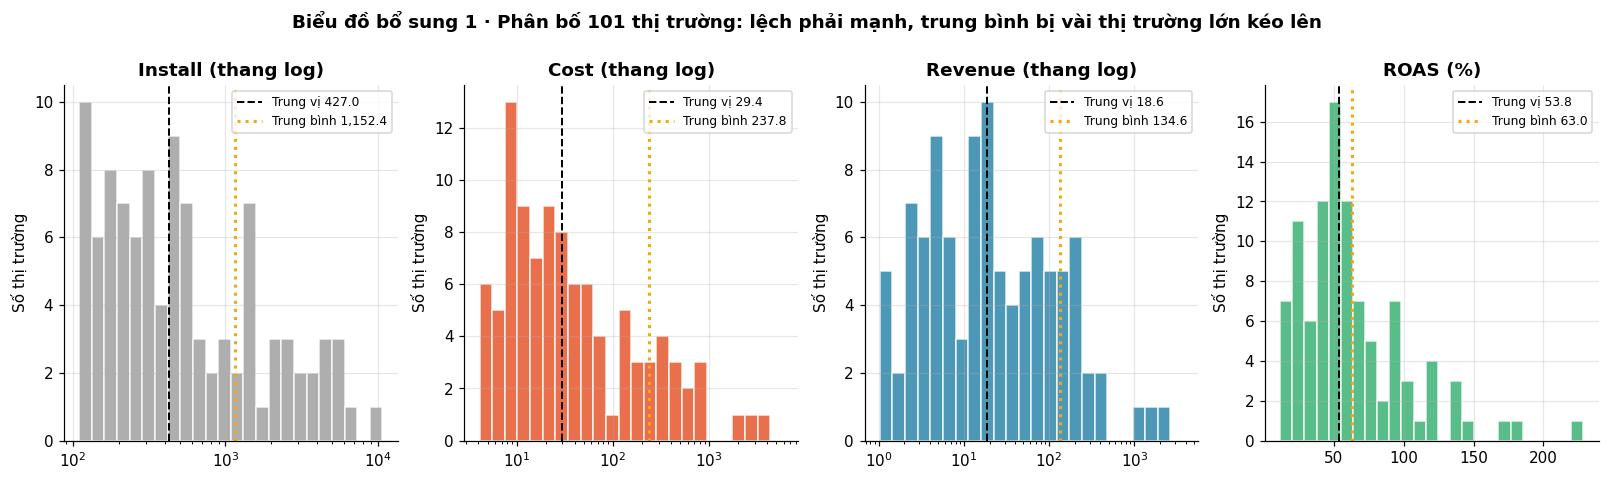

Đã lưu ảnh: outputs\figures\bieu_do_bs_01_phan_bo_thi_truong.png


In [5]:
desc = ctry[['Install', 'Cost', 'Revenue', 'CPI', 'ARPU', 'ROAS']].agg(['min', 'median', 'mean', 'max', 'std', 'skew']).T
desc.columns = ['Nhỏ nhất', 'Trung vị', 'Trung bình', 'Lớn nhất', 'Độ lệch chuẩn', 'Độ lệch phân bố (skew)']
display(desc)
save_table(desc, '2_4_thong_ke_mo_ta_thi_truong', index=True)

log('trung_vi_roas_thi_truong_%', ctry.ROAS.median())
log('trung_binh_cost_thi_truong', ctry.Cost.mean()); log('trung_vi_cost_thi_truong', ctry.Cost.median())
top_roas = ctry.nlargest(5, 'ROAS')[['Country', 'Cost', 'ROAS']]
print('\nTop 5 ROAS (lưu ý chi phí rất nhỏ):'); display(top_roas)

# Kiểm định phân phối chuẩn (Shapiro-Wilk) để chứng minh nên dùng trung vị / log
sw = []
for c in ['Install', 'Cost', 'Revenue', 'ROAS']:
    p_raw = stats.shapiro(ctry[c])[1]; p_log = stats.shapiro(np.log(ctry[c]))[1]
    sw.append([c, p_raw, p_log])
sw = pd.DataFrame(sw, columns=['Biến', 'p-value Shapiro (gốc)', 'p-value Shapiro (log)'])
print('p < 0.05 nghĩa là KHÔNG phân phối chuẩn:'); display(sw)
save_table(sw, '2_4_kiem_dinh_phan_phoi_chuan')

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, col, color in zip(axes, ['Install', 'Cost', 'Revenue', 'ROAS'], [C['inst'], C['cost'], C['rev'], C['good']]):
    data = ctry[col]
    if col != 'ROAS':
        bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 25); ax.set_xscale('log')
    else:
        bins = 25
    ax.hist(data, bins=bins, color=color, alpha=0.85, edgecolor='white')
    ax.axvline(data.median(), color='black', ls='--', lw=1.3, label=f'Trung vị {data.median():,.1f}')
    ax.axvline(data.mean(), color=C['accent'], ls=':', lw=2, label=f'Trung bình {data.mean():,.1f}')
    ax.set_title(col + (' (%)' if col == 'ROAS' else ' (thang log)' if col != 'Install' else ' (thang log)'))
    ax.set_ylabel('Số thị trường'); ax.legend(fontsize=8)
fig.suptitle('Biểu đồ bổ sung 1 · Phân bố 101 thị trường: lệch phải mạnh, trung bình bị vài thị trường lớn kéo lên', y=1.04, fontsize=12, fontweight='bold')
save_fig(fig, 'bieu_do_bs_01_phan_bo_thi_truong')

## 3. Hiệu quả theo mạng quảng cáo (Ads Network Performance)
### 3.1 Bảng hiệu quả và tỷ trọng

In [6]:
def row_from(df, label):
    s = df[['Install', 'Cost', 'Revenue']].sum(min_count=1)
    return pd.DataFrame([{'Network': label, **s.to_dict()}])

net_table = pd.concat([paid[['Network', 'Install', 'Cost', 'Revenue']],
                       row_from(paid, 'Tổng trả phí'),
                       net[net.Network == 'Organic'][['Network', 'Install', 'Cost', 'Revenue']],
                       row_from(net, 'Tổng toàn bộ')], ignore_index=True)
net_table = add_kpis(net_table)
display(net_table)
save_table(net_table, '3_1_hieu_qua_theo_mang')

# Tỷ trọng từng kênh (gồm Organic)
channels = pd.concat([paid, net[net.Network == 'Organic']], ignore_index=True)
share = pd.DataFrame({'Network': channels.Network,
                      'Install_%': pct(channels.Install, TOT_INSTALL),
                      'Cost_%': pct(channels.Cost.fillna(0), TOT_COST),
                      'Revenue_%': pct(channels.Revenue, TOT_REV)})
paid_loss = paid.Profit.sum()
share['Loss_%_of_paid_loss'] = np.where(channels.Network == 'Organic', np.nan, pct(channels.Profit, paid_loss))
share['Revenue_% - Cost_%'] = share['Revenue_%'] - share['Cost_%']
display(share)
save_table(share, '3_1_ty_trong_theo_mang')

for _, r in paid.iterrows():
    log(f'{r.Network}_ROAS_%', r.ROAS)
log('mang_roas_cao_nhat', paid.loc[paid.ROAS.idxmax(), 'Network'])
log('mang_roas_thap_nhat', paid.loc[paid.ROAS.idxmin(), 'Network'])
b = paid[paid.Network == 'Bytedance'].iloc[0]; g = paid[paid.Network == 'Google Ads'].iloc[0]
log('bytedance_ty_trong_chi_phi_%', pct(b.Cost, TOT_COST)); log('bytedance_ty_trong_doanh_thu_%', pct(b.Revenue, TOT_REV))
log('bytedance_ty_trong_lo_tra_phi_%', pct(b.Profit, paid_loss))
log('google_chi_it_hon_bytedance_%', (1 - g.Cost / b.Cost) * 100)
log('google_thu_nhieu_hon_bytedance_%', (g.Revenue / b.Revenue - 1) * 100)
fb = paid[paid.Network == 'Facebook Ads'].iloc[0]
log('bytedance_facebook_ty_trong_lo_tra_phi_%', pct(b.Profit + fb.Profit, paid_loss))
log('chuyen_100usd_bytedance_sang_google_doanh_thu_tang_usd', g.ROAS - b.ROAS)
log('organic_ty_trong_install_%', pct(org.Install, TOT_INSTALL)); log('organic_ty_trong_doanh_thu_%', pct(org.Revenue, TOT_REV))
log('arpu_organic_gap_arpu_tra_phi_lan', org.ARPU / PAID_ARPU)
log('organic_nang_roas_diem_%', OVERALL_ROAS - PAID_ROAS)

,Network,Install,Cost,Revenue,CPI,ARPU,ROAS,Profit
0,Mintegral,"36,934.000","8,152.920","4,990.150",0.221,0.135,61.207,"-3,162.770"
1,Facebook Ads,"24,056.000","5,143.890","2,473.610",0.214,0.103,48.088,"-2,670.280"
2,Google Ads,"23,550.000","4,128.270","2,967.880",0.175,0.126,71.892,"-1,160.390"
3,Bytedance,"22,639.000","6,066.690","1,680.420",0.268,0.074,27.699,"-4,386.270"
4,Unity Ads,"3,561.000",526.810,211.410,0.148,0.059,40.130,-315.400
5,Tổng trả phí,"110,740.000","24,018.580","12,323.470",0.217,0.111,51.308,"-11,695.110"
6,Organic,"5,648.000",NaN,"1,271.880",NaN,0.225,NaN,NaN
7,Tổng toàn bộ,"116,388.000","24,018.580","13,595.350",0.206,0.117,56.603,"-10,423.230"


Đã lưu bảng: outputs\tables\3_1_hieu_qua_theo_mang.csv


,Network,Install_%,Cost_%,Revenue_%,Loss_%_of_paid_loss,Revenue_% - Cost_%
0,Mintegral,31.734,33.944,36.705,27.044,2.761
1,Facebook Ads,20.669,21.416,18.195,22.832,-3.222
2,Google Ads,20.234,17.188,21.830,9.922,4.642
3,Bytedance,19.451,25.258,12.360,37.505,-12.898
4,Unity Ads,3.060,2.193,1.555,2.697,-0.638
5,Organic,4.853,0.000,9.355,NaN,9.355


Đã lưu bảng: outputs\tables\3_1_ty_trong_theo_mang.csv
• Mintegral_ROAS_%: 61.2069
• Facebook Ads_ROAS_%: 48.0883
• Google Ads_ROAS_%: 71.8916
• Bytedance_ROAS_%: 27.6991
• Unity Ads_ROAS_%: 40.1302
• mang_roas_cao_nhat: Google Ads
• mang_roas_thap_nhat: Bytedance
• bytedance_ty_trong_chi_phi_%: 25.2583
• bytedance_ty_trong_doanh_thu_%: 12.3603
• bytedance_ty_trong_lo_tra_phi_%: 37.5052
• google_chi_it_hon_bytedance_%: 31.9519
• google_thu_nhieu_hon_bytedance_%: 76.6154
• bytedance_facebook_ty_trong_lo_tra_phi_%: 60.3376
• chuyen_100usd_bytedance_sang_google_doanh_thu_tang_usd: 44.1925
• organic_ty_trong_install_%: 4.8527
• organic_ty_trong_doanh_thu_%: 9.3553
• arpu_organic_gap_arpu_tra_phi_lan: 2.0236
• organic_nang_roas_diem_%: 5.2954


### 3.2 Biểu đồ 1 · Chi phí, doanh thu và ROAS theo mạng quảng cáo

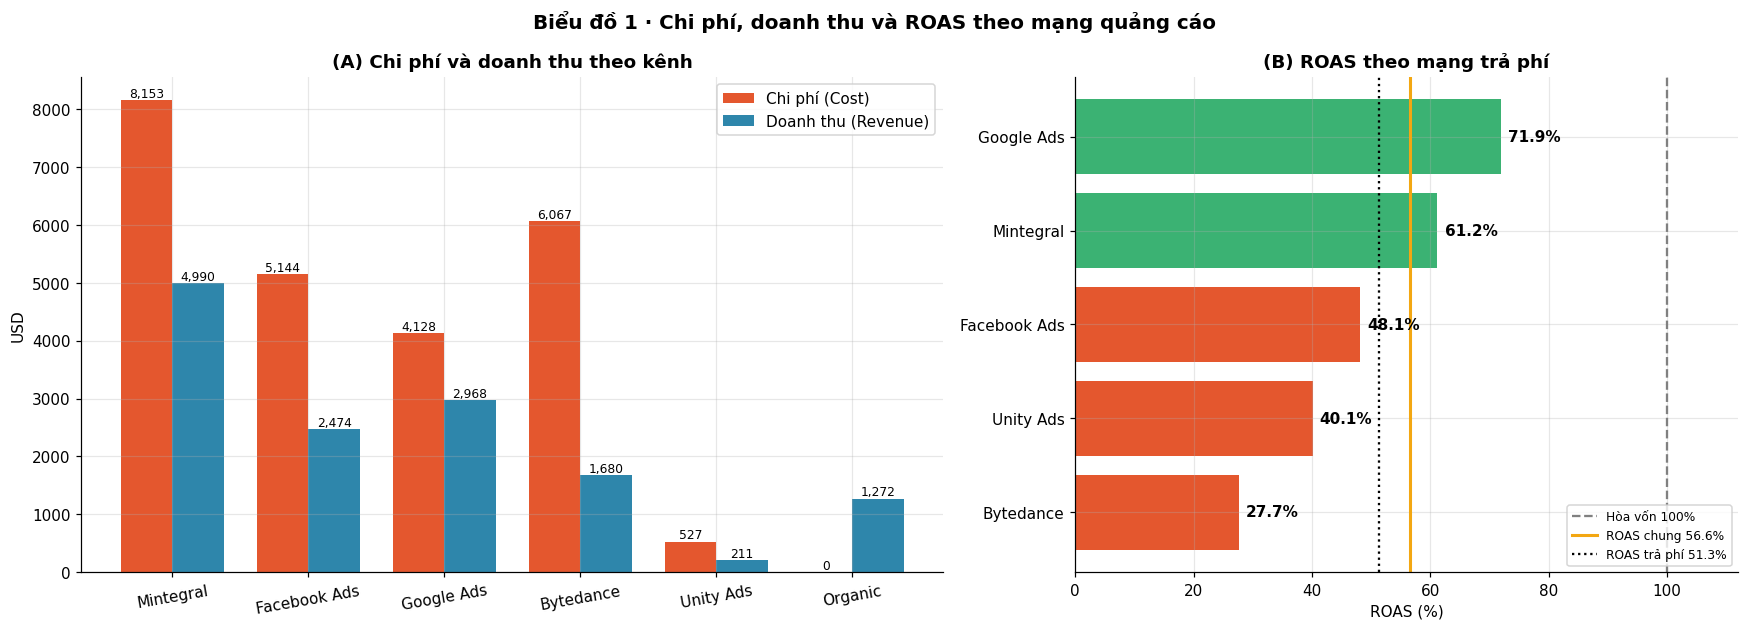

Đã lưu ảnh: outputs\figures\bieu_do_01_chi_phi_doanh_thu_roas_theo_mang.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
x = np.arange(len(channels)); w = 0.38
ax.bar(x - w/2, channels.Cost.fillna(0), w, label='Chi phí (Cost)', color=C['cost'])
ax.bar(x + w/2, channels.Revenue, w, label='Doanh thu (Revenue)', color=C['rev'])
for i, (c_, r_) in enumerate(zip(channels.Cost.fillna(0), channels.Revenue)):
    ax.text(i - w/2, c_, f'{c_:,.0f}', ha='center', va='bottom', fontsize=8)
    ax.text(i + w/2, r_, f'{r_:,.0f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(channels.Network, rotation=10)
ax.set_ylabel('USD'); ax.set_title('(A) Chi phí và doanh thu theo kênh'); ax.legend()

ax = axes[1]
p = paid.sort_values('ROAS')
colors = [C['good'] if v >= OVERALL_ROAS else C['bad'] for v in p.ROAS]
ax.barh(p.Network, p.ROAS, color=colors)
ax.axvline(100, color='grey', ls='--', lw=1.5, label='Hòa vốn 100%')
ax.axvline(OVERALL_ROAS, color=C['accent'], ls='-', lw=2, label=f'ROAS chung {OVERALL_ROAS:.1f}%')
ax.axvline(PAID_ROAS, color='black', ls=':', lw=1.5, label=f'ROAS trả phí {PAID_ROAS:.1f}%')
for i, v in enumerate(p.ROAS):
    ax.text(v + 1.2, i, f'{v:.1f}%', va='center', fontweight='bold')
ax.set_xlim(0, 112); ax.set_xlabel('ROAS (%)'); ax.set_title('(B) ROAS theo mạng trả phí'); ax.legend(loc='lower right', fontsize=8)
fig.suptitle('Biểu đồ 1 · Chi phí, doanh thu và ROAS theo mạng quảng cáo', fontsize=13, fontweight='bold')
fig.tight_layout()
save_fig(fig, 'bieu_do_01_chi_phi_doanh_thu_roas_theo_mang')

### Biểu đồ 2 · Tỷ trọng chi phí – doanh thu và cặp CPI – ARPU

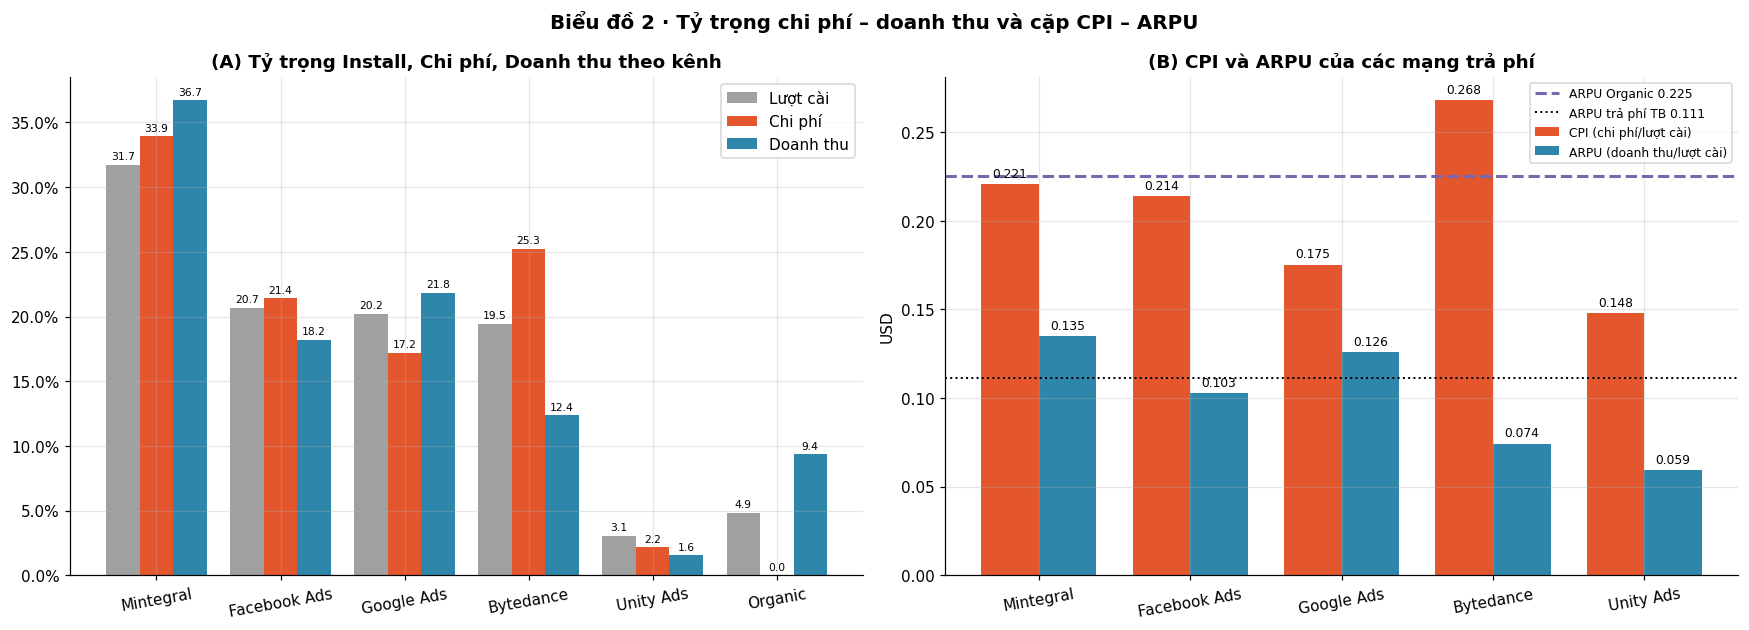

Đã lưu ảnh: outputs\figures\bieu_do_02_ty_trong_va_cpi_arpu.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
ax = axes[0]
x = np.arange(len(share)); w = 0.27
for j, (col, lab, colr) in enumerate([('Install_%', 'Lượt cài', C['inst']), ('Cost_%', 'Chi phí', C['cost']), ('Revenue_%', 'Doanh thu', C['rev'])]):
    bars = ax.bar(x + (j - 1) * w, share[col], w, label=lab, color=colr)
    for bb, v in zip(bars, share[col]):
        ax.text(bb.get_x() + bb.get_width()/2, v + 0.4, f'{v:.1f}', ha='center', fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(share.Network, rotation=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_title('(A) Tỷ trọng Install, Chi phí, Doanh thu theo kênh'); ax.legend()

ax = axes[1]
x = np.arange(len(paid)); w = 0.38
ax.bar(x - w/2, paid.CPI, w, label='CPI (chi phí/lượt cài)', color=C['cost'])
ax.bar(x + w/2, paid.ARPU, w, label='ARPU (doanh thu/lượt cài)', color=C['rev'])
for i, (c_, a_) in enumerate(zip(paid.CPI, paid.ARPU)):
    ax.text(i - w/2, c_ + 0.004, f'{c_:.3f}', ha='center', fontsize=8)
    ax.text(i + w/2, a_ + 0.004, f'{a_:.3f}', ha='center', fontsize=8)
ax.axhline(org.ARPU, color=C['organic'], ls='--', lw=2, label=f'ARPU Organic {org.ARPU:.3f}')
ax.axhline(PAID_ARPU, color='black', ls=':', lw=1.3, label=f'ARPU trả phí TB {PAID_ARPU:.3f}')
ax.set_xticks(x); ax.set_xticklabels(paid.Network, rotation=10)
ax.set_ylabel('USD'); ax.set_title('(B) CPI và ARPU của các mạng trả phí'); ax.legend(fontsize=8)
fig.suptitle('Biểu đồ 2 · Tỷ trọng chi phí – doanh thu và cặp CPI – ARPU', fontsize=13, fontweight='bold')
fig.tight_layout()
save_fig(fig, 'bieu_do_02_ty_trong_va_cpi_arpu')

### Biểu đồ bổ sung 2 · Đóng góp vào khoản lỗ & bản đồ hòa vốn CPI–ARPU
Chứng minh trực quan: không mạng nào nằm trên đường hòa vốn (ARPU = CPI); Bytedance xa đường hòa vốn nhất.

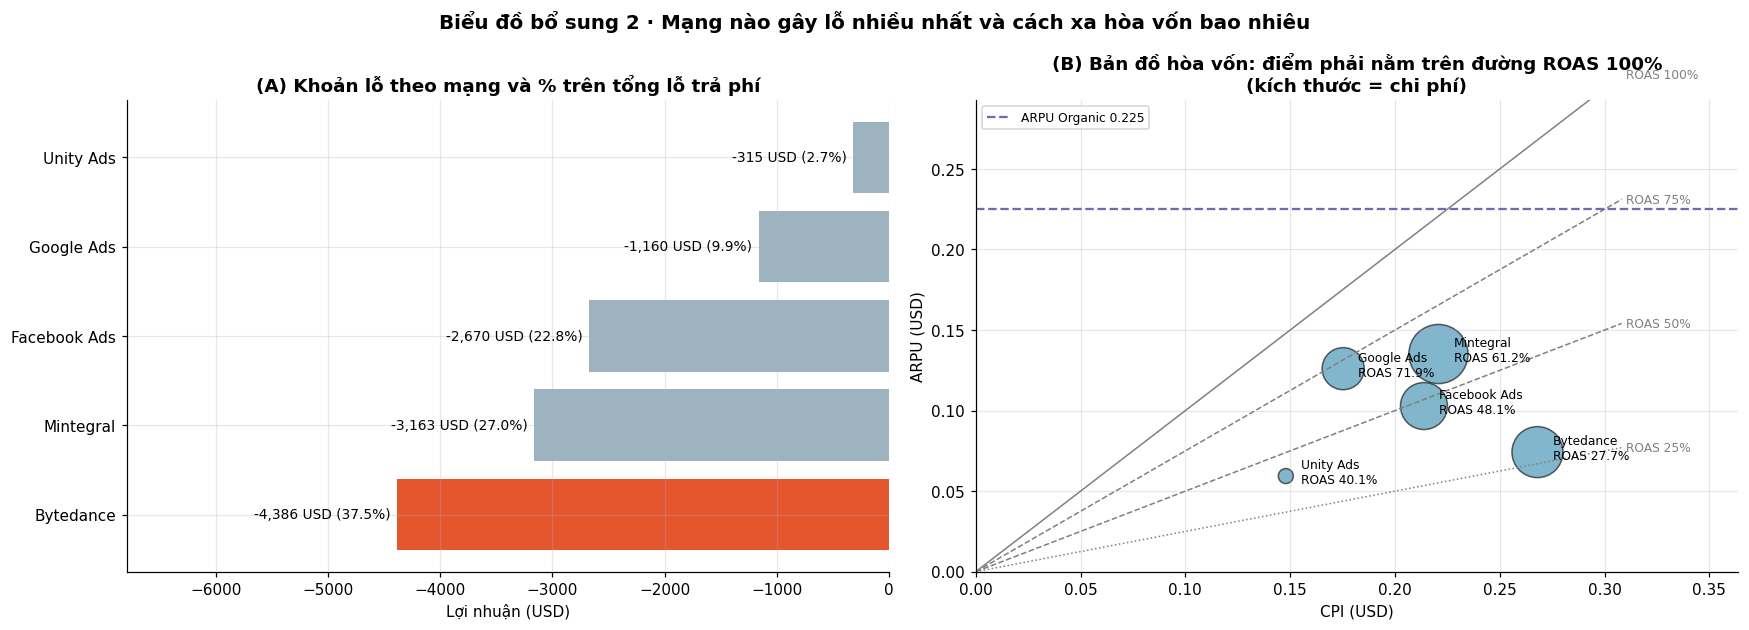

Đã lưu ảnh: outputs\figures\bieu_do_bs_02_dong_gop_lo_va_hoa_von_theo_mang.png


,Mạng,ROAS_%,CPI,ARPU,Cost_%,Revenue_%,ARPU/CPI,Vai trò gợi ý (theo quy tắc)
0,Mintegral,61.207,0.221,0.135,33.944,36.705,0.612,Duy trì & tối ưu
1,Facebook Ads,48.088,0.214,0.103,21.416,18.195,0.481,Giữ & thử nghiệm
2,Google Ads,71.892,0.175,0.126,17.188,21.830,0.719,Mở rộng
3,Bytedance,27.699,0.268,0.074,25.258,12.360,0.277,Thu hẹp
4,Unity Ads,40.130,0.148,0.059,2.193,1.555,0.401,Thu hẹp


Đã lưu bảng: outputs\tables\3_4_dinh_vi_vai_tro_mang.csv


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
ax = axes[0]
p = paid.sort_values('Profit')
bars = ax.barh(p.Network, p.Profit, color=[C['bad'] if v == p.Profit.min() else C['neutral'] for v in p.Profit])
for bb, v in zip(bars, p.Profit):
    ax.text(v - 60, bb.get_y() + bb.get_height()/2, f'{v:,.0f} USD ({v/paid_loss*100:.1f}%)', va='center', ha='right', fontsize=9)
ax.set_xlim(p.Profit.min() * 1.55, 0); ax.set_xlabel('Lợi nhuận (USD)')
ax.set_title('(A) Khoản lỗ theo mạng và % trên tổng lỗ trả phí')

ax = axes[1]
xs = np.linspace(0, paid.CPI.max() * 1.15, 50)
for lvl, ls in [(100, '-'), (75, '--'), (50, '--'), (25, ':')]:
    ax.plot(xs, xs * lvl / 100, color='grey', ls=ls, lw=1)
    ax.text(xs[-1], xs[-1] * lvl / 100, f' ROAS {lvl}%', fontsize=8, va='center', color='grey')
ax.scatter(paid.CPI, paid.ARPU, s=paid.Cost / paid.Cost.max() * 1500, color=C['rev'], alpha=0.6, edgecolor='black')
for _, r in paid.iterrows():
    ax.annotate(f'{r.Network}\nROAS {r.ROAS:.1f}%', (r.CPI, r.ARPU), textcoords='offset points', xytext=(10, -5), fontsize=8)
ax.axhline(org.ARPU, color=C['organic'], ls='--', label=f'ARPU Organic {org.ARPU:.3f}')
ax.set_xlim(0, xs[-1] * 1.18); ax.set_ylim(0, max(org.ARPU, paid.ARPU.max()) * 1.3)
ax.set_xlabel('CPI (USD)'); ax.set_ylabel('ARPU (USD)'); ax.legend(loc='upper left', fontsize=8)
ax.set_title('(B) Bản đồ hòa vốn: điểm phải nằm trên đường ROAS 100%\n(kích thước = chi phí)')
fig.suptitle('Biểu đồ bổ sung 2 · Mạng nào gây lỗ nhiều nhất và cách xa hòa vốn bao nhiêu', fontsize=13, fontweight='bold')
fig.tight_layout()
save_fig(fig, 'bieu_do_bs_02_dong_gop_lo_va_hoa_von_theo_mang')

roles = pd.DataFrame({
    'Mạng': paid.Network, 'ROAS_%': paid.ROAS, 'CPI': paid.CPI, 'ARPU': paid.ARPU,
    'Cost_%': pct(paid.Cost, TOT_COST), 'Revenue_%': pct(paid.Revenue, TOT_REV),
    'ARPU/CPI': paid.ARPU / paid.CPI})
roles['Vai trò gợi ý (theo quy tắc)'] = np.select(
    [roles['ROAS_%'] == roles['ROAS_%'].max(),
     (roles['ROAS_%'] >= OVERALL_ROAS),
     (roles['ROAS_%'] < OVERALL_ROAS) & (roles['ROAS_%'] >= 45),
     (roles['ROAS_%'] < 45)],
    ['Mở rộng', 'Duy trì & tối ưu', 'Giữ & thử nghiệm', 'Thu hẹp'], default='')
display(roles)
save_table(roles, '3_4_dinh_vi_vai_tro_mang')

## 4. Thị trường quốc gia & phân nhóm (Country Performance & Segmentation)
### 4.1 Quy luật Pareto & Tier 1

In [10]:
TOTC = ctry[['Install', 'Cost', 'Revenue']].sum()
ctry['cum_cost_%'] = ctry.Cost.cumsum() / TOTC.Cost * 100
ctry['cum_rev_%_cost_order'] = ctry.Revenue.cumsum() / TOTC.Revenue * 100

def n_to_reach(series, thr=0.8):
    s = series.sort_values(ascending=False).cumsum() / series.sum()
    return int((s < thr - 1e-12).sum() + 1)

log('so_thi_truong_dat_80%_chi_phi', n_to_reach(ctry.Cost))
log('so_thi_truong_dat_80%_doanh_thu', n_to_reach(ctry.Revenue))
log('so_thi_truong_dat_80%_install', n_to_reach(ctry.Install))
for n in [4, 10, 20]:
    log(f'top{n}_chi_phi_ty_trong_%', ctry.head(n).Cost.sum() / TOTC.Cost * 100)
    log(f'top{n}_doanh_thu_ty_trong_%', ctry.head(n).Revenue.sum() / TOTC.Revenue * 100)

def group_summary(df, by):
    g = df.groupby(by).agg(So_TT=('Country', 'count'), Install=('Install', 'sum'),
                           Cost=('Cost', 'sum'), Revenue=('Revenue', 'sum'))
    g = add_kpis(g)
    g['Install_%'] = pct(g.Install, df.Install.sum()); g['Cost_%'] = pct(g.Cost, df.Cost.sum())
    g['Revenue_%'] = pct(g.Revenue, df.Revenue.sum())
    loss_total = df.loc[df.Profit < 0, 'Profit'].sum()
    g['Lo_cua_TT_lo_%'] = pct(df[df.Profit < 0].groupby(by).Profit.sum().reindex(g.index).fillna(0), loss_total)
    return g

ctry['Nhom_Tier'] = np.where(ctry.Code.isin(TIER1), 'Tier 1 (JP, US, KR, DE)', 'Còn lại (97 TT)')
tier_tab = group_summary(ctry, 'Nhom_Tier')
display(tier_tab)
save_table(tier_tab, '4_1_tier1_vs_con_lai', index=True)
t1 = tier_tab.loc['Tier 1 (JP, US, KR, DE)']; rest = tier_tab.loc['Còn lại (97 TT)']
log('tier1_cpi_gap_con_lai_lan', t1.CPI / rest.CPI); log('tier1_arpu_gap_con_lai_lan', t1.ARPU / rest.ARPU)
log('tier1_roas_%', t1.ROAS); log('con_lai_roas_%', rest.ROAS)

ctry['Nhom_Top20'] = np.where(ctry.index < 20, 'Top 20 chi phí', 'Đuôi dài (81 TT)')
top20_tab = group_summary(ctry, 'Nhom_Top20')
display(top20_tab)
save_table(top20_tab, '4_1_top20_vs_duoi_dai', index=True)

top10 = ctry.head(10)[['Country', 'Install', 'Cost', 'Revenue', 'CPI', 'ARPU', 'ROAS', 'Profit']]
display(top10)
save_table(top10, '4_1_top10_thi_truong_chi_phi')

• so_thi_truong_dat_80%_chi_phi: 13
• so_thi_truong_dat_80%_doanh_thu: 14
• so_thi_truong_dat_80%_install: 30
• top4_chi_phi_ty_trong_%: 59.5011
• top4_doanh_thu_ty_trong_%: 61.8613
• top10_chi_phi_ty_trong_%: 75.6353
• top10_doanh_thu_ty_trong_%: 74.5535
• top20_chi_phi_ty_trong_%: 88.1622
• top20_doanh_thu_ty_trong_%: 86.3423


,So_TT,Install,Cost,Revenue,CPI,ARPU,ROAS,Profit,Install_%,Cost_%,Revenue_%,Lo_cua_TT_lo_%
Nhom_Tier,,,,,,,,,,,,
Còn lại (97 TT),97,89632,"9,727.270","5,185.090",0.109,0.058,53.305,"-4,542.180",77.011,40.499,38.139,44.120
"Tier 1 (JP, US, KR, DE)",4,26756,"14,291.310","8,410.260",0.534,0.314,58.849,"-5,881.050",22.989,59.501,61.861,55.880


Đã lưu bảng: outputs\tables\4_1_tier1_vs_con_lai.csv
• tier1_cpi_gap_con_lai_lan: 4.9218
• tier1_arpu_gap_con_lai_lan: 5.4337
• tier1_roas_%: 58.8488
• con_lai_roas_%: 53.3047


,So_TT,Install,Cost,Revenue,CPI,ARPU,ROAS,Profit,Install_%,Cost_%,Revenue_%,Lo_cua_TT_lo_%
Nhom_Top20,,,,,,,,,,,,
Top 20 chi phí,20,74513,"21,175.310","11,738.540",0.284,0.158,55.435,"-9,436.770",64.021,88.162,86.342,89.666
Đuôi dài (81 TT),81,41875,"2,843.270","1,856.810",0.068,0.044,65.305,-986.460,35.979,11.838,13.658,10.334


Đã lưu bảng: outputs\tables\4_1_top20_vs_duoi_dai.csv


,Country,Install,Cost,Revenue,CPI,ARPU,ROAS,Profit
0,Japan (JP),10685,"5,836.810","3,740.130",0.546,0.350,64.078,"-2,096.680"
1,United States (US),6454,"3,879.180","2,266.180",0.601,0.351,58.419,"-1,613.000"
2,South Korea (KR),4780,"2,749.650","1,389.640",0.575,0.291,50.539,"-1,360.010"
3,Germany (DE),4837,"1,825.670","1,014.310",0.377,0.210,55.558,-811.360
4,Italy (IT),2675,763.970,267.530,0.286,0.100,35.018,-496.440
5,Taiwan (TW),2295,743.690,290.700,0.324,0.127,39.089,-452.990
6,South Africa (ZA),2492,708.540,353.220,0.284,0.142,49.852,-355.320
7,Czechia (CZ),2677,670.360,348.340,0.250,0.130,51.963,-322.020
8,Spain (ES),2942,537.900,238.220,0.183,0.081,44.287,-299.680
9,Canada (CA),1583,450.760,227.540,0.285,0.144,50.479,-223.220


Đã lưu bảng: outputs\tables\4_1_top10_thi_truong_chi_phi.csv


### Biểu đồ 3 · Top 20 thị trường theo chi phí và đường Pareto lũy kế

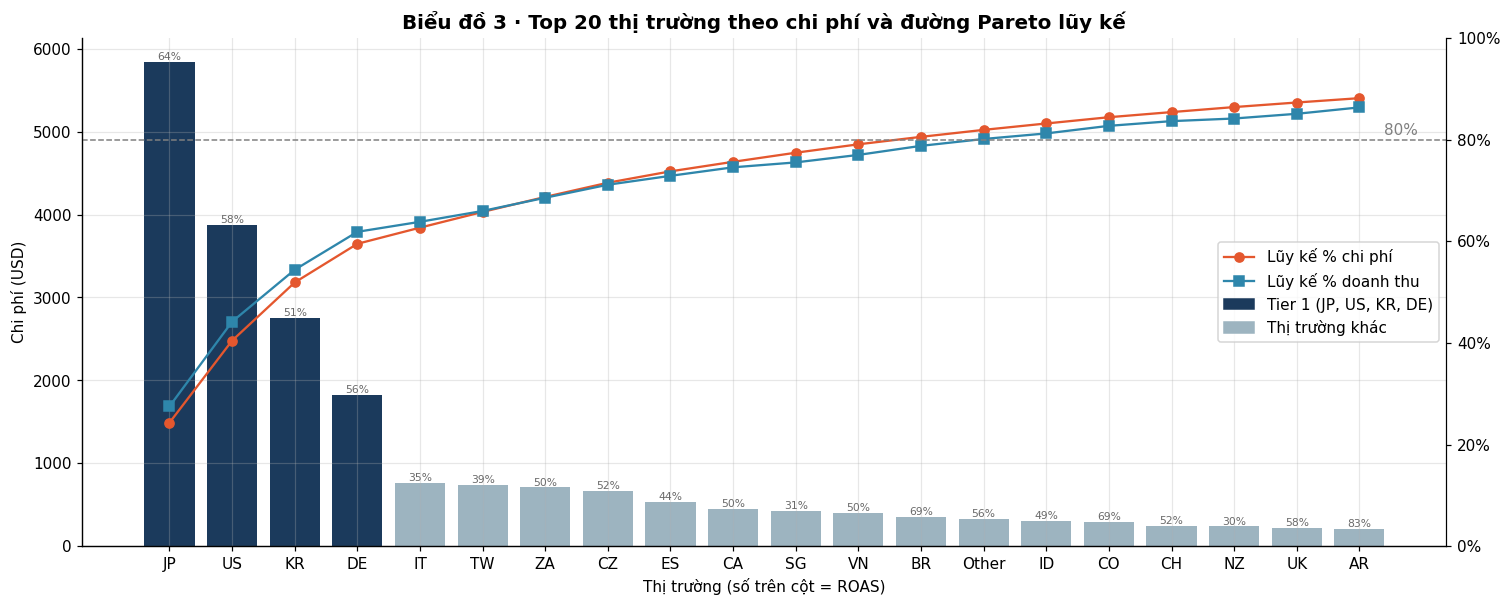

Đã lưu ảnh: outputs\figures\bieu_do_03_pareto_top20.png


In [11]:
top20 = ctry.head(20)
fig, ax = plt.subplots(figsize=(16, 6))
colors = [C['tier1'] if c in TIER1 else C['neutral'] for c in top20.Code]
bars = ax.bar(top20.Code, top20.Cost, color=colors)
for bb, r in zip(bars, top20.itertuples()):
    ax.text(bb.get_x() + bb.get_width()/2, r.Cost, f'{r.ROAS:.0f}%', ha='center', va='bottom', fontsize=7, color='dimgray')
ax.set_ylabel('Chi phí (USD)'); ax.set_xlabel('Thị trường (số trên cột = ROAS)')
ax2 = ax.twinx()
ax2.plot(top20.Code, top20['cum_cost_%'], marker='o', color=C['cost'], label='Lũy kế % chi phí')
ax2.plot(top20.Code, top20['cum_rev_%_cost_order'], marker='s', color=C['rev'], label='Lũy kế % doanh thu')
ax2.axhline(80, color='grey', ls='--', lw=1); ax2.text(19.4, 81, '80%', color='grey')
ax2.set_ylim(0, 100); ax2.yaxis.set_major_formatter(mtick.PercentFormatter()); ax2.grid(False)
ax2.spines['right'].set_visible(True)
from matplotlib.patches import Patch
h, l = ax2.get_legend_handles_labels()
h += [Patch(color=C['tier1']), Patch(color=C['neutral'])]; l += ['Tier 1 (JP, US, KR, DE)', 'Thị trường khác']
ax2.legend(h, l, loc='center right')
ax.set_title('Biểu đồ 3 · Top 20 thị trường theo chi phí và đường Pareto lũy kế', fontsize=13)
save_fig(fig, 'bieu_do_03_pareto_top20')

### Biểu đồ bổ sung 3 · Giá cao có mua được chất lượng / hoàn vốn? (tương quan Spearman)
Kiểm định thống kê cho nhận định “CPI cao không đồng nghĩa ROAS cao”.

,Cặp biến,Spearman rho,p-value,Kết luận
0,CPI – ARPU,0.618,0.000,Có ý nghĩa (p<0.05)
1,CPI – ROAS,-0.172,0.085,Chưa đủ ý nghĩa
2,Install – ROAS,0.142,0.156,Chưa đủ ý nghĩa
3,Cost – ROAS,0.082,0.416,Chưa đủ ý nghĩa


Đã lưu bảng: outputs\tables\4_1_tuong_quan_spearman.csv
• spearman_CPI_ARPU: rho=0.618, p=0.0000
• spearman_CPI_ROAS: rho=-0.172, p=0.0853
• spearman_Install_ROAS: rho=0.142, p=0.1559
• spearman_Cost_ROAS: rho=0.082, p=0.4157


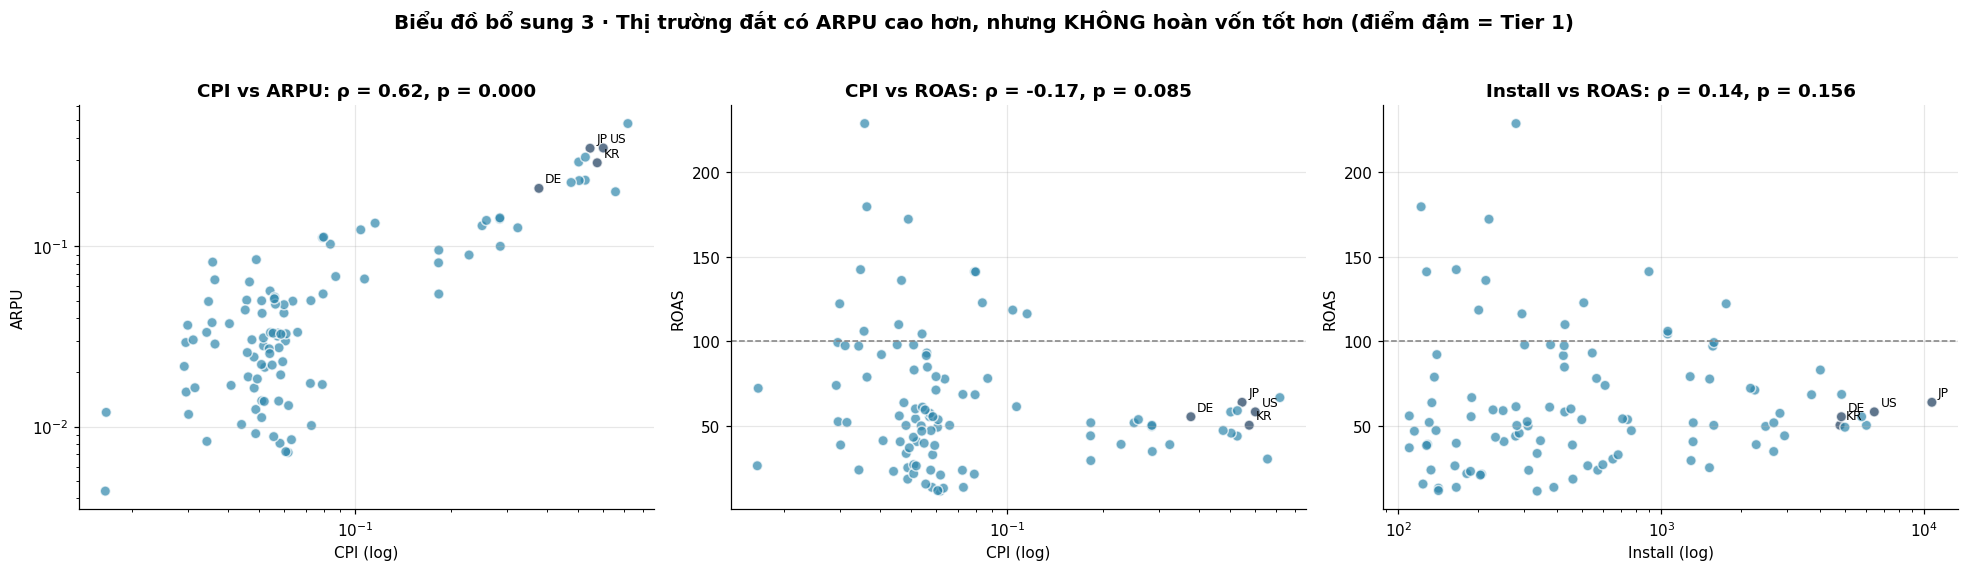

Đã lưu ảnh: outputs\figures\bieu_do_bs_03_tuong_quan_cpi_arpu_roas.png


In [12]:
pairs = [('CPI', 'ARPU'), ('CPI', 'ROAS'), ('Install', 'ROAS'), ('Cost', 'ROAS')]
corr_rows = []
for a, b_ in pairs:
    rho, pv = stats.spearmanr(ctry[a], ctry[b_])
    corr_rows.append([f'{a} – {b_}', rho, pv, 'Có ý nghĩa (p<0.05)' if pv < 0.05 else 'Chưa đủ ý nghĩa'])
corr = pd.DataFrame(corr_rows, columns=['Cặp biến', 'Spearman rho', 'p-value', 'Kết luận'])
display(corr)
save_table(corr, '4_1_tuong_quan_spearman')
for r in corr.itertuples():
    log(f'spearman_{r[1].replace(" – ", "_")}', f'rho={r[2]:.3f}, p={r[3]:.4f}')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (a, b_) in zip(axes, pairs[:3]):
    colr = [C['tier1'] if c in TIER1 else C['rev'] for c in ctry.Code]
    ax.scatter(ctry[a], ctry[b_], c=colr, alpha=0.7, edgecolor='white', s=45)
    ax.set_xscale('log')
    if b_ == 'ARPU': ax.set_yscale('log')
    if b_ == 'ROAS': ax.axhline(100, color='grey', ls='--', lw=1)
    rho, pv = stats.spearmanr(ctry[a], ctry[b_])
    ax.set_title(f'{a} vs {b_}: ρ = {rho:.2f}, p = {pv:.3f}')
    ax.set_xlabel(a + ' (log)'); ax.set_ylabel(b_)
    for _, r in ctry[ctry.Code.isin(TIER1)].iterrows():
        ax.annotate(r.Code, (r[a], r[b_]), fontsize=8, xytext=(4, 4), textcoords='offset points')
fig.suptitle('Biểu đồ bổ sung 3 · Thị trường đắt có ARPU cao hơn, nhưng KHÔNG hoàn vốn tốt hơn (điểm đậm = Tier 1)', fontsize=13, fontweight='bold', y=1.03)
fig.tight_layout()
save_fig(fig, 'bieu_do_bs_03_tuong_quan_cpi_arpu_roas')

### 4.2 Ma trận 4 góc phần tư: ROAS và quy mô — Biểu đồ 4

,So_TT,Install,Cost,Revenue,CPI,ARPU,ROAS,Profit,Install_%,Cost_%,Revenue_%,Lo_cua_TT_lo_%,TT tiêu biểu (theo chi phí)
Quadrant,,,,,,,,,,,,,
ROAS cao – Quy mô lớn,15,46859,"11,325.700","7,237.450",0.242,0.154,63.903,"-4,088.250",40.261,47.154,53.235,39.002,"JP, US, BR, CO, AR, PH, MX, TR"
ROAS cao – Quy mô nhỏ,29,9765,"1,018.360",852.190,0.104,0.087,83.683,-166.170,8.390,4.240,6.268,2.384,"UK, AU, HK, PL, UY, PA, CL, GT"
ROAS thấp – Quy mô lớn (đốt tiền),15,46536,"10,095.580","4,902.980",0.217,0.105,48.566,"-5,192.600",39.984,42.032,36.064,49.339,"KR, DE, IT, TW, ZA, CZ, ES, CA"
ROAS thấp – Quy mô nhỏ,42,13228,"1,578.940",602.730,0.119,0.046,38.173,-976.210,11.365,6.574,4.433,9.276,"SG, FR, SE, AT, DK, BO, TZ, AM"


Đã lưu bảng: outputs\tables\4_2_ma_tran_4_goc.csv
• hai_nhom_quy_mo_lon_ty_trong_chi_phi_%: 89.1863
• hai_nhom_quy_mo_lon_ty_trong_lo_rong_%: 89.0401
Dòng "Other" thuộc nhóm: ['ROAS thấp – Quy mô lớn (đốt tiền)']


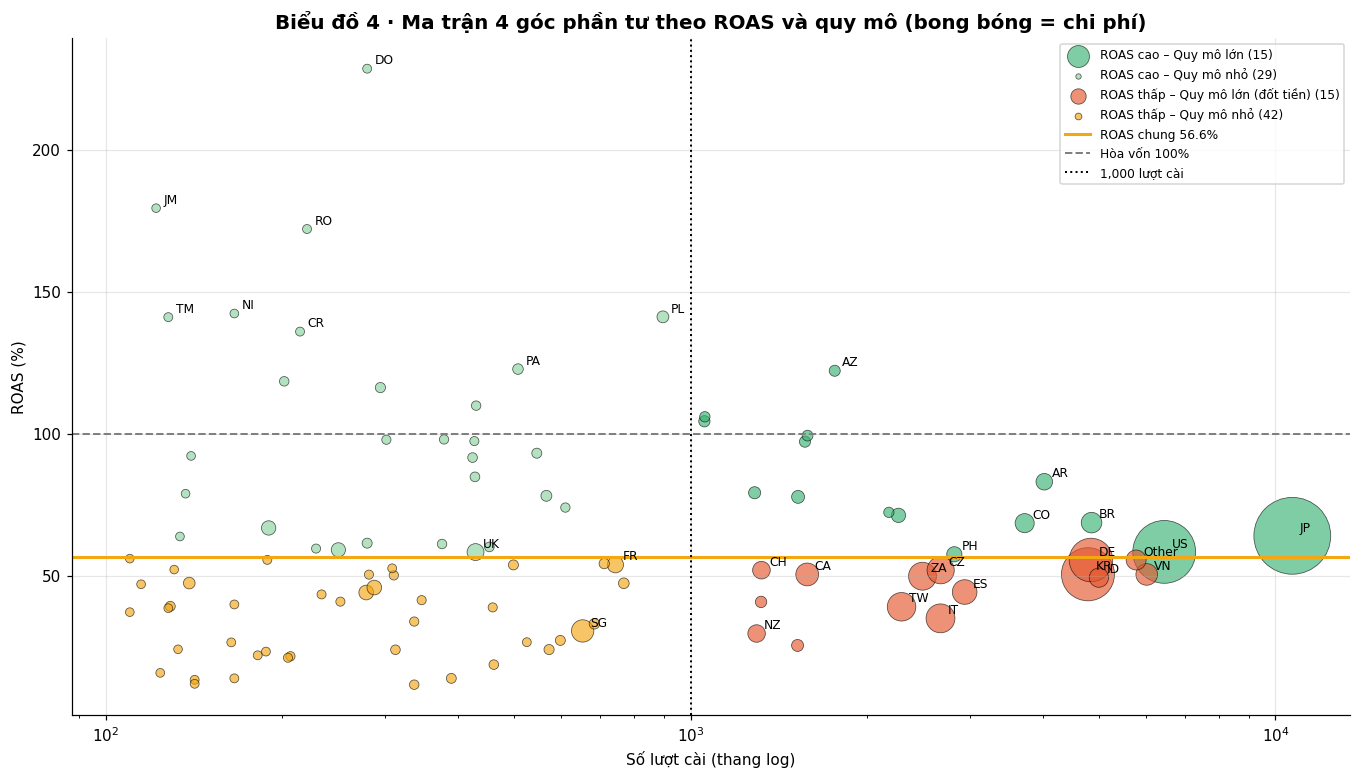

Đã lưu ảnh: outputs\figures\bieu_do_04_ma_tran_4_goc_phan_tu.png


In [13]:
Q_ORDER = ['ROAS cao – Quy mô lớn', 'ROAS cao – Quy mô nhỏ', 'ROAS thấp – Quy mô lớn (đốt tiền)', 'ROAS thấp – Quy mô nhỏ']
Q_COLORS = dict(zip(Q_ORDER, [C['good'], '#8BD3A0', C['bad'], C['warn']]))
hi = ctry.ROAS >= OVERALL_ROAS; big = ctry.Install >= INSTALL_THR
ctry['Quadrant'] = np.select([hi & big, hi & ~big, ~hi & big, ~hi & ~big], Q_ORDER, default='')

quad = group_summary(ctry, 'Quadrant').reindex(Q_ORDER)
quad['TT tiêu biểu (theo chi phí)'] = [', '.join(ctry[ctry.Quadrant == q].nlargest(8, 'Cost').Code) for q in Q_ORDER]
display(quad)
save_table(quad, '4_2_ma_tran_4_goc', index=True)
big_q = quad.loc[[Q_ORDER[0], Q_ORDER[2]]]
log('hai_nhom_quy_mo_lon_ty_trong_chi_phi_%', big_q['Cost_%'].sum())
log('hai_nhom_quy_mo_lon_ty_trong_lo_rong_%', big_q.Profit.sum() / (TOTC.Revenue - TOTC.Cost) * 100)
print('Dòng "Other" thuộc nhóm:', ctry.loc[ctry.Code == 'Other', 'Quadrant'].tolist())

fig, ax = plt.subplots(figsize=(15, 8))
for q in Q_ORDER:
    d = ctry[ctry.Quadrant == q]
    ax.scatter(d.Install, d.ROAS, s=30 + d.Cost / ctry.Cost.max() * 2500, color=Q_COLORS[q],
               alpha=0.65, edgecolor='black', lw=0.5, label=f'{q} ({len(d)})')
ax.set_xscale('log')
ax.axhline(OVERALL_ROAS, color=C['accent'], lw=2, label=f'ROAS chung {OVERALL_ROAS:.1f}%')
ax.axhline(100, color='grey', ls='--', lw=1.3, label='Hòa vốn 100%')
ax.axvline(INSTALL_THR, color='black', ls=':', lw=1.3, label=f'{INSTALL_THR:,} lượt cài')
lab = ctry[(ctry.Cost >= 150) | (ctry.ROAS >= 120)]
for _, r in lab.iterrows():
    ax.annotate(r.Code, (r.Install, r.ROAS), fontsize=8, xytext=(5, 3), textcoords='offset points')
ax.set_xlabel('Số lượt cài (thang log)'); ax.set_ylabel('ROAS (%)')
ax.set_title('Biểu đồ 4 · Ma trận 4 góc phần tư theo ROAS và quy mô (bong bóng = chi phí)', fontsize=13)
lg = ax.legend(loc='upper right', fontsize=8, markerscale=0.4)
save_fig(fig, 'bieu_do_04_ma_tran_4_goc_phan_tu')

### 4.3 Điểm rò rỉ ngân sách — Biểu đồ 5

• so_thi_truong_lo: 87
• tong_lo_cac_thi_truong_lo: -10524.41
• so_thi_truong_lai: 14
• tong_lai_cac_thi_truong_lai: 101.18
• top10_lo_ty_trong_tong_lo_%: 77.0171
• top10_lo_danh_sach: JP (-2,097), US (-1,613), KR (-1,360), DE (-811), IT (-496), TW (-453), ZA (-355), CZ (-322), ES (-300), SG (-298)
• so_thi_truong_roas_>=100: 14
• chi_phi_thi_truong_roas_>=100: 386.87
• ty_trong_chi_phi_thi_truong_roas_>=100_%: 1.6107
• danh_sach_roas_>=100: PL, EC, AZ, PA, BY, CL, PT, MD, RO, TM, CR, DO, NI, JM
• so_thi_truong_roas_<30: 19
• chi_phi_thi_truong_roas_<30: 572.27
Đã lưu bảng: outputs\tables\4_3_top10_lo.csv
Đã lưu bảng: outputs\tables\4_3_thi_truong_roas_tren_100.csv


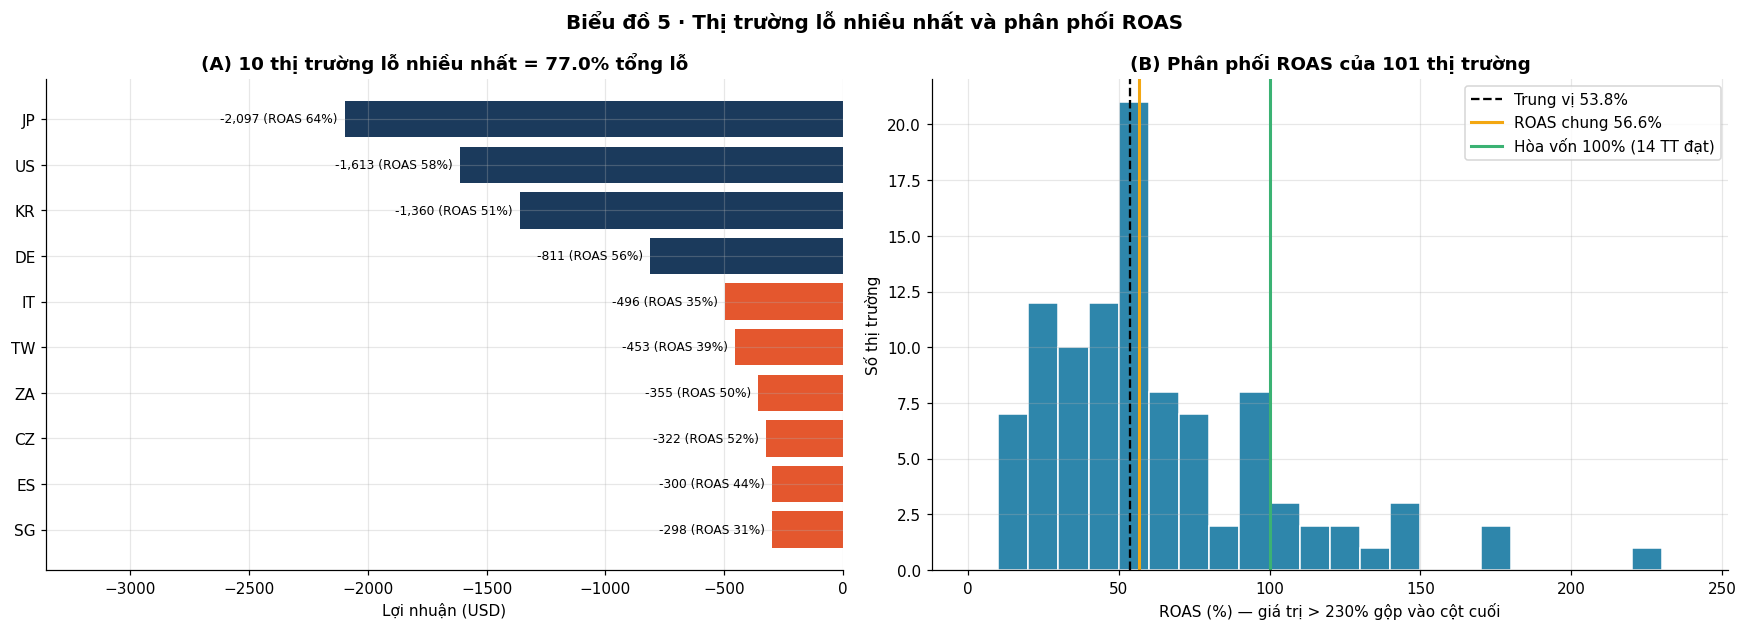

Đã lưu ảnh: outputs\figures\bieu_do_05_ro_ri_ngan_sach.png


In [14]:
loss = ctry[ctry.Profit < 0]; gain = ctry[ctry.Profit >= 0]
log('so_thi_truong_lo', len(loss)); log('tong_lo_cac_thi_truong_lo', loss.Profit.sum())
log('so_thi_truong_lai', len(gain)); log('tong_lai_cac_thi_truong_lai', gain.Profit.sum())
top_loss = ctry.nsmallest(10, 'Profit')
log('top10_lo_ty_trong_tong_lo_%', top_loss.Profit.sum() / loss.Profit.sum() * 100)
log('top10_lo_danh_sach', ', '.join(f'{r.Code} ({r.Profit:,.0f})' for r in top_loss.itertuples()))
roas100 = ctry[ctry.ROAS >= 100]
log('so_thi_truong_roas_>=100', len(roas100)); log('chi_phi_thi_truong_roas_>=100', roas100.Cost.sum())
log('ty_trong_chi_phi_thi_truong_roas_>=100_%', roas100.Cost.sum() / TOTC.Cost * 100)
log('danh_sach_roas_>=100', ', '.join(roas100.Code))
roas30 = ctry[ctry.ROAS < 30]
log('so_thi_truong_roas_<30', len(roas30)); log('chi_phi_thi_truong_roas_<30', roas30.Cost.sum())
save_table(top_loss[['Country', 'Cost', 'Revenue', 'ROAS', 'Profit']], '4_3_top10_lo')
save_table(roas100[['Country', 'Install', 'Cost', 'Revenue', 'ROAS', 'Profit']], '4_3_thi_truong_roas_tren_100')

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
ax = axes[0]
tl = top_loss.sort_values('Profit', ascending=False)
bars = ax.barh(tl.Code, tl.Profit, color=[C['tier1'] if c in TIER1 else C['bad'] for c in tl.Code])
for bb, r in zip(bars, tl.itertuples()):
    ax.text(r.Profit - 30, bb.get_y() + bb.get_height()/2, f'{r.Profit:,.0f} (ROAS {r.ROAS:.0f}%)', ha='right', va='center', fontsize=8)
ax.set_xlim(tl.Profit.min() * 1.6, 0); ax.set_xlabel('Lợi nhuận (USD)')
ax.set_title(f'(A) 10 thị trường lỗ nhiều nhất = {top_loss.Profit.sum()/loss.Profit.sum()*100:.1f}% tổng lỗ')

ax = axes[1]
clipped = ctry.ROAS.clip(upper=235)
ax.hist(clipped, bins=np.arange(0, 250, 10), color=C['rev'], edgecolor='white')
ax.axvline(ctry.ROAS.median(), color='black', ls='--', label=f'Trung vị {ctry.ROAS.median():.1f}%')
ax.axvline(OVERALL_ROAS, color=C['accent'], lw=2, label=f'ROAS chung {OVERALL_ROAS:.1f}%')
ax.axvline(100, color=C['good'], lw=2, label=f'Hòa vốn 100% ({len(roas100)} TT đạt)')
ax.set_xlabel('ROAS (%) — giá trị > 230% gộp vào cột cuối'); ax.set_ylabel('Số thị trường')
ax.set_title('(B) Phân phối ROAS của 101 thị trường'); ax.legend()
fig.suptitle('Biểu đồ 5 · Thị trường lỗ nhiều nhất và phân phối ROAS', fontsize=13, fontweight='bold')
fig.tight_layout()
save_fig(fig, 'bieu_do_05_ro_ri_ngan_sach')

### Biểu đồ bổ sung 4 · “Hình phễu”: ROAS dao động mạnh ở thị trường chi ít
Chứng minh giả thuyết H5 — ROAS rất cao ở đuôi dài có thể do mẫu nhỏ.

,count,median,std,min,max
Cost_bin,,,,,
< 20 USD,41,50.149,50.878,11.963,228.571
20–100,33,61.487,36.507,11.651,141.187
100–500,18,54.724,13.557,29.674,83.121
> 500,9,50.539,9.220,35.018,64.078


Đã lưu bảng: outputs\tables\4_3_do_dao_dong_roas_theo_quy_mo_chi.csv


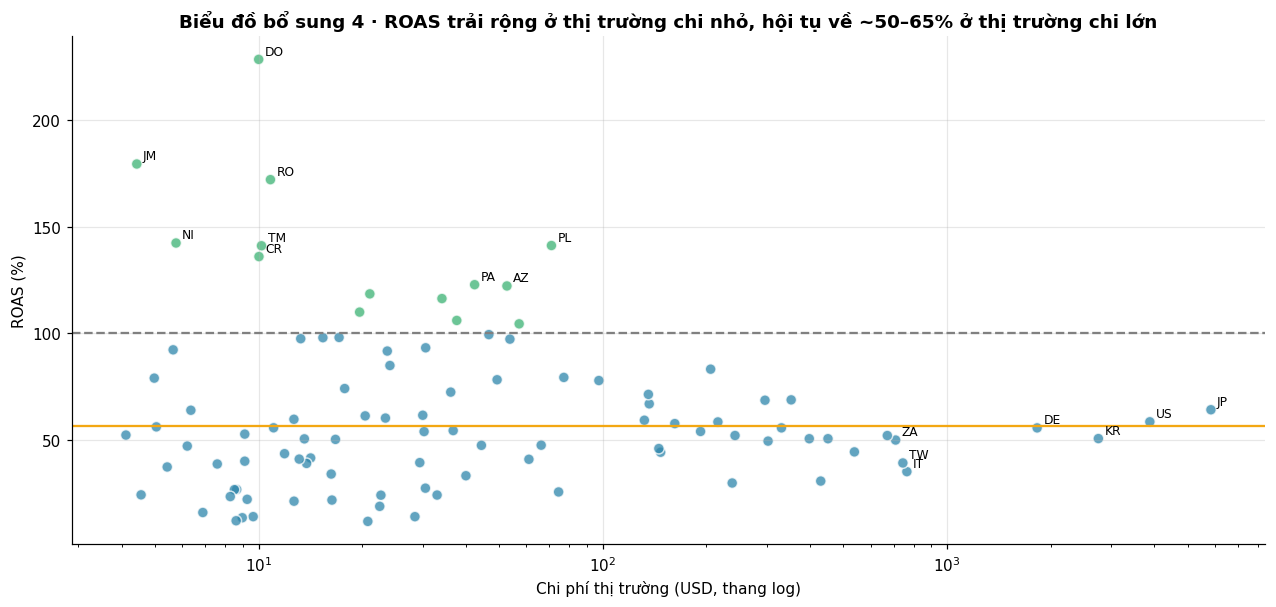

Đã lưu ảnh: outputs\figures\bieu_do_bs_04_pheu_roas_theo_chi_phi.png


In [15]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.scatter(ctry.Cost, ctry.ROAS, c=np.where(ctry.ROAS >= 100, C['good'], C['rev']), alpha=0.75, edgecolor='white', s=50)
ax.set_xscale('log'); ax.axhline(100, color='grey', ls='--'); ax.axhline(OVERALL_ROAS, color=C['accent'])
for _, r in ctry[(ctry.ROAS >= 120) | (ctry.Cost >= 700)].iterrows():
    ax.annotate(r.Code, (r.Cost, r.ROAS), fontsize=8, xytext=(4, 3), textcoords='offset points')
bins = [0, 20, 100, 500, 1e5]
ctry['Cost_bin'] = pd.cut(ctry.Cost, bins, labels=['< 20 USD', '20–100', '100–500', '> 500'])
spread = ctry.groupby('Cost_bin').ROAS.agg(['count', 'median', 'std', 'min', 'max'])
display(spread); save_table(spread, '4_3_do_dao_dong_roas_theo_quy_mo_chi', index=True)
ax.set_xlabel('Chi phí thị trường (USD, thang log)'); ax.set_ylabel('ROAS (%)')
ax.set_title('Biểu đồ bổ sung 4 · ROAS trải rộng ở thị trường chi nhỏ, hội tụ về ~50–65% ở thị trường chi lớn', fontsize=12)
save_fig(fig, 'bieu_do_bs_04_pheu_roas_theo_chi_phi')

## 5. Ứng dụng AI / Machine Learning
### 5.1 Phân cụm K-Means (log + z-score; CPI, ARPU, ROAS, Install)

In [16]:
FEATURES = ['CPI', 'ARPU', 'ROAS', 'Install']
X = np.log(ctry[FEATURES])
scaler = StandardScaler(); Xs = scaler.fit_transform(X)

sil, inertia = [], []
for k in K_RANGE:
    km_k = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(Xs)
    sil.append(silhouette_score(Xs, km_k.labels_)); inertia.append(km_k.inertia_)
k_tab = pd.DataFrame({'k': list(K_RANGE), 'Silhouette': sil, 'Inertia (SSE)': inertia})
display(k_tab); save_table(k_tab, '5_1_chon_so_cum_k')

km = KMeans(n_clusters=K_CHOSEN, n_init=N_INIT, random_state=RANDOM_STATE).fit(Xs)
ctry['cluster_id'] = km.labels_
log('silhouette_k_chon', silhouette_score(Xs, km.labels_))
log('k_silhouette_cao_nhat', int(k_tab.loc[k_tab.Silhouette.idxmax(), 'k']))

# ---- Đặt tên cụm tự động theo đặc điểm (cho k = 4) ----
prof = add_kpis(ctry.groupby('cluster_id')[['Install', 'Cost', 'Revenue']].sum())
names = {}
if K_CHOSEN == 4:
    t1_id = prof.CPI.idxmax(); r_ = prof.drop(t1_id)
    niche_id = r_.ROAS.idxmax(); low_id = r_.ROAS.idxmin()
    emg_id = [i for i in r_.index if i not in (niche_id, low_id)][0]
    names = {t1_id: 'Tier 1 – Chi tiêu lớn, đốt tiền', emg_id: 'Mới nổi – Install lớn, chi phí thấp',
             niche_id: 'Ngách ROI cao', low_id: 'Hiệu quả thấp – Quy mô nhỏ'}
else:
    names = {i: f'Cụm {i}' for i in prof.index}
ctry['Cluster'] = ctry.cluster_id.map(names)
CL_ORDER = [names[i] for i in prof.sort_values('Cost', ascending=False).index]
CL_COLORS = dict(zip(CL_ORDER, CLUSTER_COLORS))

cl_tab = group_summary(ctry, 'Cluster').reindex(CL_ORDER)
cl_tab['Lo_rong_%'] = cl_tab.Profit / (TOTC.Revenue - TOTC.Cost) * 100
cl_tab['TT tiêu biểu'] = [', '.join(ctry[ctry.Cluster == c].nlargest(10, 'Cost').Code) for c in CL_ORDER]
display(cl_tab); save_table(cl_tab, '5_1_ket_qua_phan_cum', index=True)
for c in CL_ORDER:
    r = cl_tab.loc[c]
    log(f'cum[{c}]', f'{int(r.So_TT)} TT | Cost {r.Cost:,.2f} ({r["Cost_%"]:.1f}%) | ROAS {r.ROAS:.1f}% | Profit {r.Profit:,.2f} | Lỗ ròng {r["Lo_rong_%"]:.1f}%')

members = ctry.groupby('Cluster').Code.apply(lambda s: ', '.join(s)).reindex(CL_ORDER).reset_index()
members.columns = ['Cụm', 'Danh sách thị trường']
save_table(members, '5_1_thanh_vien_tung_cum')

,k,Silhouette,Inertia (SSE)
0,2,0.404,256.140
1,3,0.383,156.860
2,4,0.369,120.435
3,5,0.373,97.310
4,6,0.391,75.089
5,7,0.395,66.971
6,8,0.382,59.726


Đã lưu bảng: outputs\tables\5_1_chon_so_cum_k.csv
• silhouette_k_chon: 0.3689
• k_silhouette_cao_nhat: 2


,So_TT,Install,Cost,Revenue,CPI,ARPU,ROAS,Profit,Install_%,Cost_%,Revenue_%,Lo_cua_TT_lo_%,Lo_rong_%,TT tiêu biểu
Cluster,,,,,,,,,,,,,,
"Tier 1 – Chi tiêu lớn, đốt tiền",21,47141,"20,140.380","11,036.850",0.427,0.234,54.800,"-9,103.530",40.503,83.853,81.181,86.499,87.339,"JP, US, KR, DE, IT, TW, ZA, CZ, ES, CA"
"Mới nổi – Install lớn, chi phí thấp",20,49924,"2,799.670","1,843.500",0.056,0.037,65.847,-956.170,42.894,11.656,13.560,9.242,9.173,"VN, BR, Other, ID, CO, AR, PH, MX, TR, BE"
Ngách ROI cao,29,9393,579.350,577.440,0.062,0.061,99.670,-1.910,8.070,2.412,4.247,0.823,0.018,"PL, UY, PA, CL, GT, GE, MY, HN, PE, KE"
Hiệu quả thấp – Quy mô nhỏ,31,9930,499.180,137.560,0.050,0.014,27.557,-361.620,8.532,2.078,1.012,3.436,3.469,"MN, TZ, CD, TJ, SO, LA, GA, GN, RU, MG"


Đã lưu bảng: outputs\tables\5_1_ket_qua_phan_cum.csv
• cum[Tier 1 – Chi tiêu lớn, đốt tiền]: 21 TT | Cost 20,140.38 (83.9%) | ROAS 54.8% | Profit -9,103.53 | Lỗ ròng 87.3%
• cum[Mới nổi – Install lớn, chi phí thấp]: 20 TT | Cost 2,799.67 (11.7%) | ROAS 65.8% | Profit -956.17 | Lỗ ròng 9.2%
• cum[Ngách ROI cao]: 29 TT | Cost 579.35 (2.4%) | ROAS 99.7% | Profit -1.91 | Lỗ ròng 0.0%
• cum[Hiệu quả thấp – Quy mô nhỏ]: 31 TT | Cost 499.18 (2.1%) | ROAS 27.6% | Profit -361.62 | Lỗ ròng 3.5%
Đã lưu bảng: outputs\tables\5_1_thanh_vien_tung_cum.csv


### Biểu đồ 6 · Kết quả phân cụm K-Means

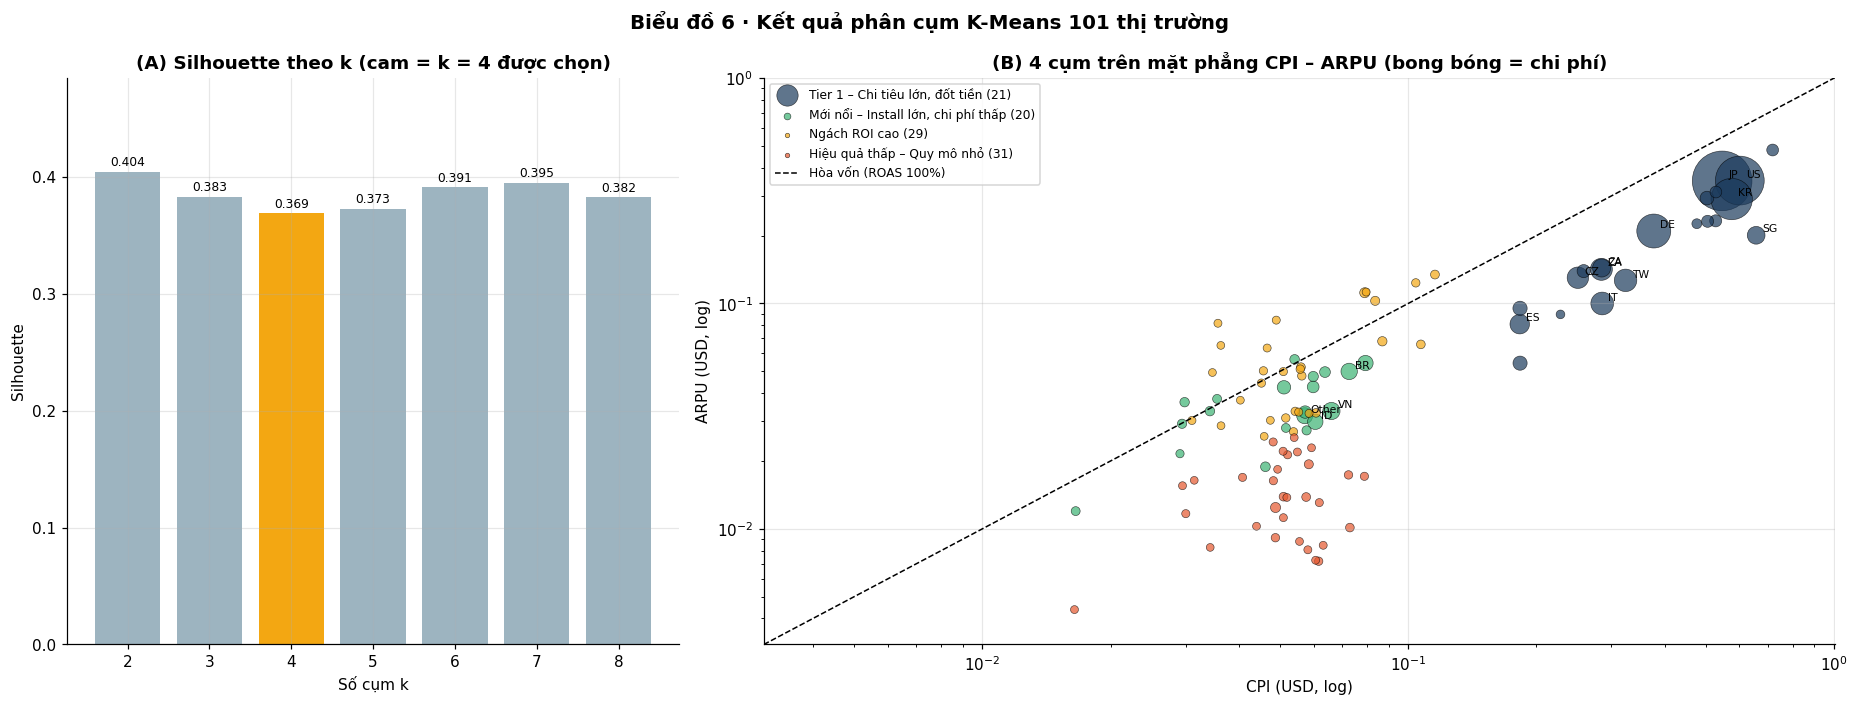

Đã lưu ảnh: outputs\figures\bieu_do_06_phan_cum_kmeans.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [0.8, 1.4]})
ax = axes[0]
cols = [C['accent'] if k == K_CHOSEN else C['neutral'] for k in K_RANGE]
bars = ax.bar(list(K_RANGE), sil, color=cols)
for bb, v in zip(bars, sil):
    ax.text(bb.get_x() + bb.get_width()/2, v + 0.005, f'{v:.3f}', ha='center', fontsize=8)
ax.set_xlabel('Số cụm k'); ax.set_ylabel('Silhouette'); ax.set_title(f'(A) Silhouette theo k (cam = k = {K_CHOSEN} được chọn)')
ax.set_ylim(0, max(sil) * 1.2)

ax = axes[1]
for c in CL_ORDER:
    d = ctry[ctry.Cluster == c]
    ax.scatter(d.CPI, d.ARPU, s=25 + d.Cost / ctry.Cost.max() * 1500, color=CL_COLORS[c], alpha=0.7,
               edgecolor='black', lw=0.4, label=f'{c} ({len(d)})')
lim = [ctry[['CPI', 'ARPU']].min().min() * 0.7, ctry[['CPI', 'ARPU']].max().max() * 1.4]
ax.plot(lim, lim, 'k--', lw=1, label='Hòa vốn (ROAS 100%)')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
for _, r in ctry.nlargest(15, 'Cost').iterrows():
    ax.annotate(r.Code, (r.CPI, r.ARPU), fontsize=7, xytext=(4, 2), textcoords='offset points')
ax.set_xlabel('CPI (USD, log)'); ax.set_ylabel('ARPU (USD, log)')
ax.set_title('(B) 4 cụm trên mặt phẳng CPI – ARPU (bong bóng = chi phí)'); ax.legend(fontsize=8, markerscale=0.5, loc='upper left')
fig.suptitle('Biểu đồ 6 · Kết quả phân cụm K-Means 101 thị trường', fontsize=13, fontweight='bold')
fig.tight_layout()
save_fig(fig, 'bieu_do_06_phan_cum_kmeans')

### Biểu đồ bổ sung 5 · Hồ sơ cụm & kiểm tra độ ổn định của phân cụm
- Heatmap tâm cụm (z-score) cho biết **đặc trưng nào định nghĩa từng cụm**.
- Adjusted Rand Index (ARI): so sánh với (1) 20 seed khác nhau, (2) bỏ ROAS khỏi đặc trưng (vì ROAS = ARPU/CPI có thể bị đếm đôi). ARI gần 1 = phân cụm ổn định.

• ARI_trung_binh_20_seed: 0.9737
• ARI_min_20_seed: 0.969
• ARI_khi_bo_ROAS: 0.783


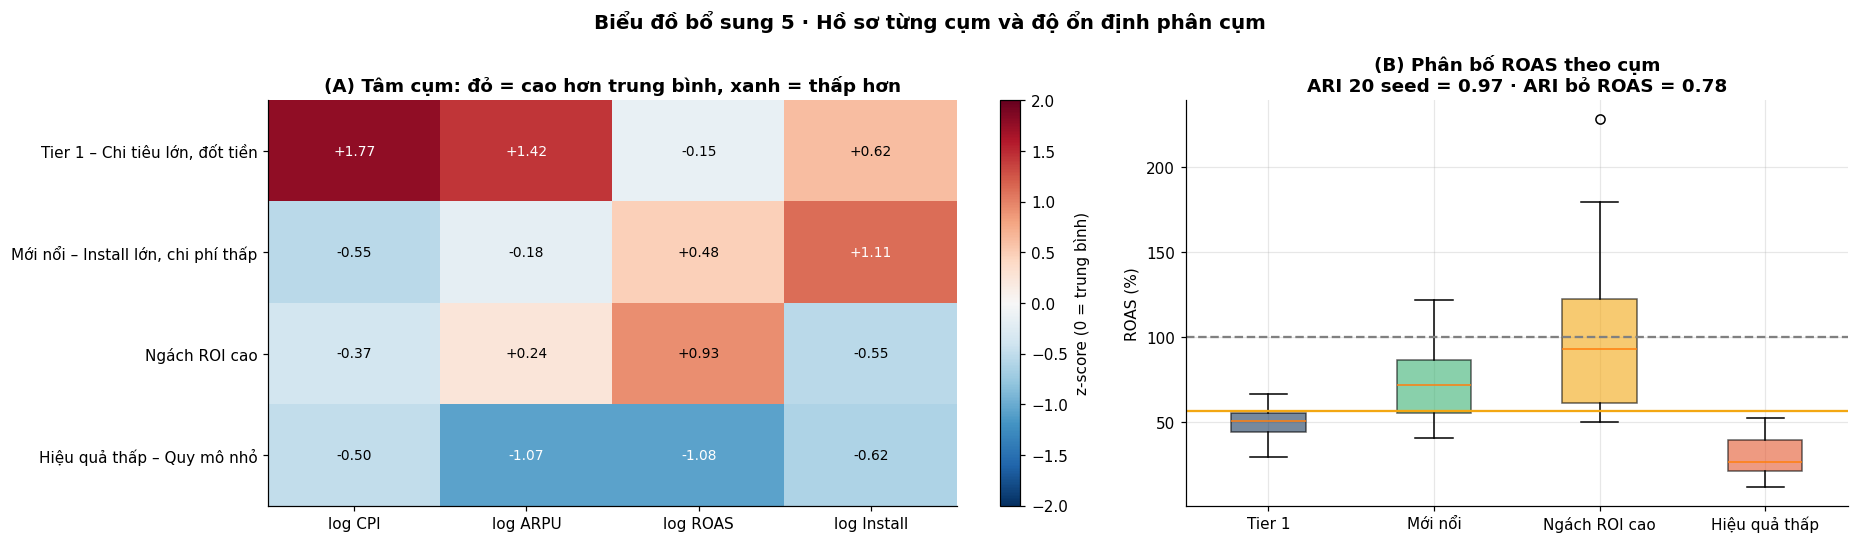

Đã lưu ảnh: outputs\figures\bieu_do_bs_05_ho_so_cum_va_do_on_dinh.png
Đã lưu bảng: outputs\tables\5_1_tam_cum_zscore.csv


In [18]:
centers = pd.DataFrame(km.cluster_centers_, columns=FEATURES).rename(index=names).reindex(CL_ORDER)
ari_seed = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=s).fit_predict(Xs)) for s in range(20)]
Xs_noroas = StandardScaler().fit_transform(np.log(ctry[['CPI', 'ARPU', 'Install']]))
ari_noroas = adjusted_rand_score(km.labels_, KMeans(n_clusters=K_CHOSEN, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(Xs_noroas))
log('ARI_trung_binh_20_seed', np.mean(ari_seed)); log('ARI_min_20_seed', np.min(ari_seed))
log('ARI_khi_bo_ROAS', ari_noroas)

fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
im = ax.imshow(centers.values, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels([f'log {f}' for f in FEATURES])
ax.set_yticks(range(len(CL_ORDER))); ax.set_yticklabels(CL_ORDER); ax.grid(False)
for i in range(centers.shape[0]):
    for j in range(centers.shape[1]):
        ax.text(j, i, f'{centers.values[i, j]:+.2f}', ha='center', va='center', fontsize=9,
                color='white' if abs(centers.values[i, j]) > 1 else 'black')
fig.colorbar(im, ax=ax, label='z-score (0 = trung bình)')
ax.set_title('(A) Tâm cụm: đỏ = cao hơn trung bình, xanh = thấp hơn')

ax = axes[1]
data = [ctry[ctry.Cluster == c].ROAS for c in CL_ORDER]
bp = ax.boxplot(data, patch_artist=True)
ax.set_xticks(range(1, len(CL_ORDER) + 1)); ax.set_xticklabels([c.split(' – ')[0] for c in CL_ORDER])
for patch, c in zip(bp['boxes'], CL_ORDER):
    patch.set_facecolor(CL_COLORS[c]); patch.set_alpha(0.6)
ax.axhline(100, color='grey', ls='--'); ax.axhline(OVERALL_ROAS, color=C['accent'])
ax.set_ylabel('ROAS (%)'); ax.set_title(f'(B) Phân bố ROAS theo cụm\nARI 20 seed = {np.mean(ari_seed):.2f} · ARI bỏ ROAS = {ari_noroas:.2f}')
fig.suptitle('Biểu đồ bổ sung 5 · Hồ sơ từng cụm và độ ổn định phân cụm', fontsize=13, fontweight='bold')
fig.tight_layout()
save_fig(fig, 'bieu_do_bs_05_ho_so_cum_va_do_on_dinh')
save_table(centers, '5_1_tam_cum_zscore', index=True)

### 5.2 Tối ưu phân bổ ngân sách bằng Linear Programming
**Mô hình.** Với mỗi đơn vị *i* (mạng hoặc thị trường): chi phí mới = c_i − d_i + u_i, trong đó d_i là phần cắt, u_i là phần tăng.

- Mục tiêu: max Σ ROAS_i·(c_i − d_i) + α·ROAS_i·u_i  (α = 1 lạc quan; α = 0,7 thận trọng)
- Ràng buộc: Σu_i = Σd_i (tổng ngân sách không đổi); 0 ≤ d_i, u_i ≤ 50%·c_i
- Bộ giải: `scipy.optimize.linprog(method='highs')`

In [19]:
def optimize_budget(cost, roas_pct, alpha=1.0, max_change=MAX_CHANGE):
    cost = np.asarray(cost, float); r = np.asarray(roas_pct, float) / 100; n = len(cost)
    c = np.concatenate([r, -alpha * r])                    # linprog cực tiểu hóa -> đổi dấu doanh thu
    A_eq = np.concatenate([-np.ones(n), np.ones(n)])[None, :]
    bounds = [(0, max_change * ci) for ci in cost] * 2
    res = linprog(c, A_eq=A_eq, b_eq=[0], bounds=bounds, method='highs')
    assert res.success, res.message
    d, u = res.x[:n], res.x[n:]
    new_cost = cost - d + u
    new_rev = r * (cost - d) + alpha * r * u
    return new_cost, new_rev

# ---- Theo mạng (chỉ trả phí) ----
nc_cons, nr_cons = optimize_budget(paid.Cost, paid.ROAS, CONSERVATIVE_FACTOR)
nc_opt, nr_opt = optimize_budget(paid.Cost, paid.ROAS, 1.0)
lp_net = pd.DataFrame({'Mạng': paid.Network, 'Hiện tại (USD)': paid.Cost.values, 'ROAS_%': paid.ROAS.values,
                       'Thận trọng (USD)': nc_cons, 'Thận trọng Δ%': (nc_cons / paid.Cost.values - 1) * 100,
                       'Lạc quan (USD)': nc_opt, 'Lạc quan Δ%': (nc_opt / paid.Cost.values - 1) * 100,
                       'DT thận trọng': nr_cons, 'DT lạc quan': nr_opt})
summary_net = pd.DataFrame({
    'Chỉ tiêu': ['Ngân sách (USD)', 'Doanh thu trả phí dự kiến (USD)', 'Thay đổi doanh thu (%)', 'Doanh thu tăng thêm (USD)', 'ROAS trả phí (%)'],
    'Hiện tại': [TOT_COST, PAID_REV, 0, 0, PAID_ROAS],
    'Thận trọng': [nc_cons.sum(), nr_cons.sum(), (nr_cons.sum() / PAID_REV - 1) * 100, nr_cons.sum() - PAID_REV, nr_cons.sum() / nc_cons.sum() * 100],
    'Lạc quan': [nc_opt.sum(), nr_opt.sum(), (nr_opt.sum() / PAID_REV - 1) * 100, nr_opt.sum() - PAID_REV, nr_opt.sum() / nc_opt.sum() * 100]})
display(lp_net); display(summary_net)
save_table(lp_net, '5_2_lp_theo_mang'); save_table(summary_net, '5_2_lp_theo_mang_tong_hop')
log('lp_mang_doanh_thu_tang_than_trong_%', summary_net.loc[2, 'Thận trọng']); log('lp_mang_doanh_thu_tang_lac_quan_%', summary_net.loc[2, 'Lạc quan'])
log('lp_mang_roas_than_trong_%', summary_net.loc[4, 'Thận trọng']); log('lp_mang_roas_lac_quan_%', summary_net.loc[4, 'Lạc quan'])

# ---- Theo thị trường (loại "Other") ----
cm = ctry[ctry.Code != 'Other'].reset_index(drop=True)
cc_cons, cr_cons = optimize_budget(cm.Cost, cm.ROAS, CONSERVATIVE_FACTOR)
cc_opt, cr_opt = optimize_budget(cm.Cost, cm.ROAS, 1.0)
lp_ctry = pd.DataFrame({'Country': cm.Country, 'Code': cm.Code, 'Cluster': cm.Cluster, 'Hiện tại (USD)': cm.Cost, 'ROAS_%': cm.ROAS,
                        'Thận trọng (USD)': cc_cons, 'Thận trọng Δ USD': cc_cons - cm.Cost, 'Thận trọng Δ%': (cc_cons / cm.Cost - 1) * 100,
                        'Lạc quan (USD)': cc_opt, 'Lạc quan Δ%': (cc_opt / cm.Cost - 1) * 100})
lp_ctry['Hành động (thận trọng)'] = np.select([lp_ctry['Thận trọng Δ%'] < -0.5, lp_ctry['Thận trọng Δ%'] > 0.5], ['Giảm', 'Tăng'], 'Giữ nguyên')
cur_rev_c = (cm.Revenue).sum()
summary_ctry = pd.DataFrame({
    'Chỉ tiêu': ['Ngân sách (USD)', 'Doanh thu dự kiến (USD)', 'Thay đổi doanh thu (%)', 'Doanh thu tăng thêm (USD)', 'ROAS (%)'],
    'Hiện tại': [cm.Cost.sum(), cur_rev_c, 0, 0, cur_rev_c / cm.Cost.sum() * 100],
    'Thận trọng': [cc_cons.sum(), cr_cons.sum(), (cr_cons.sum() / cur_rev_c - 1) * 100, cr_cons.sum() - cur_rev_c, cr_cons.sum() / cc_cons.sum() * 100],
    'Lạc quan': [cc_opt.sum(), cr_opt.sum(), (cr_opt.sum() / cur_rev_c - 1) * 100, cr_opt.sum() - cur_rev_c, cr_opt.sum() / cc_opt.sum() * 100]})
display(summary_ctry)
print(lp_ctry['Hành động (thận trọng)'].value_counts())
save_table(lp_ctry, '5_2_lp_theo_thi_truong'); save_table(summary_ctry, '5_2_lp_theo_thi_truong_tong_hop')
log('lp_tt_doanh_thu_tang_than_trong_%', summary_ctry.loc[2, 'Thận trọng']); log('lp_tt_doanh_thu_tang_lac_quan_%', summary_ctry.loc[2, 'Lạc quan'])
log('lp_tt_doanh_thu_tang_than_trong_usd', summary_ctry.loc[3, 'Thận trọng']); log('lp_tt_doanh_thu_tang_lac_quan_usd', summary_ctry.loc[3, 'Lạc quan'])
log('lp_tt_roas_than_trong_%', summary_ctry.loc[4, 'Thận trọng']); log('lp_tt_roas_lac_quan_%', summary_ctry.loc[4, 'Lạc quan'])
vc = lp_ctry['Hành động (thận trọng)'].value_counts()
log('lp_tt_so_giam_giu_tang', f"{vc.get('Giảm', 0)} / {vc.get('Giữ nguyên', 0)} / {vc.get('Tăng', 0)}")
log('lp_tt_tong_giam_usd', lp_ctry.loc[lp_ctry['Thận trọng Δ USD'] < 0, 'Thận trọng Δ USD'].sum())
full_up = lp_ctry[lp_ctry['Thận trọng Δ%'] > 49.5]
log('lp_tt_so_tt_tang_toi_da_50%', len(full_up)); log('lp_tt_chi_phi_hien_tai_nhom_tang_toi_da', full_up['Hiện tại (USD)'].sum())
partial = lp_ctry[(lp_ctry['Thận trọng Δ%'] > 0.5) & (lp_ctry['Thận trọng Δ%'] <= 49.5)]
log('lp_tt_tang_mot_phan', ', '.join(f"{r['Code']} ({r['Thận trọng Δ USD']:+,.2f} USD, {r['Thận trọng Δ%']:+.1f}%)"
                                      for _, r in partial.iterrows()) or 'Không có')

,Mạng,Hiện tại (USD),ROAS_%,Thận trọng (USD),Thận trọng Δ%,Lạc quan (USD),Lạc quan Δ%,DT thận trọng,DT lạc quan
0,Mintegral,"8,152.920",61.207,"9,385.535",15.119,"11,957.480",46.665,"5,518.262","7,318.803"
1,Facebook Ads,"5,143.890",48.088,"5,143.890",0.000,"2,571.945",-50.000,"2,473.610","1,236.805"
2,Google Ads,"4,128.270",71.892,"6,192.405",50.000,"6,192.405",50.000,"4,006.638","4,451.820"
3,Bytedance,"6,066.690",27.699,"3,033.345",-50.000,"3,033.345",-50.000,840.210,840.210
4,Unity Ads,526.810,40.130,263.405,-50.000,263.405,-50.000,105.705,105.705


,Chỉ tiêu,Hiện tại,Thận trọng,Lạc quan
0,Ngân sách (USD),"24,018.580","24,018.580","24,018.580"
1,Doanh thu trả phí dự kiến (USD),"12,323.470","12,944.425","13,953.343"
2,Thay đổi doanh thu (%),0.000,5.039,13.226
3,Doanh thu tăng thêm (USD),0.000,620.955,"1,629.873"
4,ROAS trả phí (%),51.308,53.893,58.094


Đã lưu bảng: outputs\tables\5_2_lp_theo_mang.csv
Đã lưu bảng: outputs\tables\5_2_lp_theo_mang_tong_hop.csv
• lp_mang_doanh_thu_tang_than_trong_%: 5.0388
• lp_mang_doanh_thu_tang_lac_quan_%: 13.2258
• lp_mang_roas_than_trong_%: 53.8934
• lp_mang_roas_lac_quan_%: 58.094


,Chỉ tiêu,Hiện tại,Thận trọng,Lạc quan
0,Ngân sách (USD),"23,688.350","23,688.350","23,688.350"
1,Doanh thu dự kiến (USD),"13,411.860","13,718.864","14,505.055"
2,Thay đổi doanh thu (%),0.000,2.289,8.151
3,Doanh thu tăng thêm (USD),0.000,307.004,"1,093.195"
4,ROAS (%),56.618,57.914,61.233


Hành động (thận trọng)
Tăng          35
Giảm          35
Giữ nguyên    30
Name: count, dtype: int64
Đã lưu bảng: outputs\tables\5_2_lp_theo_thi_truong.csv
Đã lưu bảng: outputs\tables\5_2_lp_theo_thi_truong_tong_hop.csv
• lp_tt_doanh_thu_tang_than_trong_%: 2.289
• lp_tt_doanh_thu_tang_lac_quan_%: 8.151
• lp_tt_doanh_thu_tang_than_trong_usd: 307.0038
• lp_tt_doanh_thu_tang_lac_quan_usd: 1093.1948
• lp_tt_roas_than_trong_%: 57.914
• lp_tt_roas_lac_quan_%: 61.2329
• lp_tt_so_giam_giu_tang: 35 / 30 / 35
• lp_tt_tong_giam_usd: -1708.125
• lp_tt_so_tt_tang_toi_da_50%: 34
• lp_tt_chi_phi_hien_tai_nhom_tang_toi_da: 2025.54
• lp_tt_tang_mot_phan: JP (+695.36 USD, +11.9%)


### Biểu đồ 7 · Phân bổ ngân sách trước và sau tối ưu

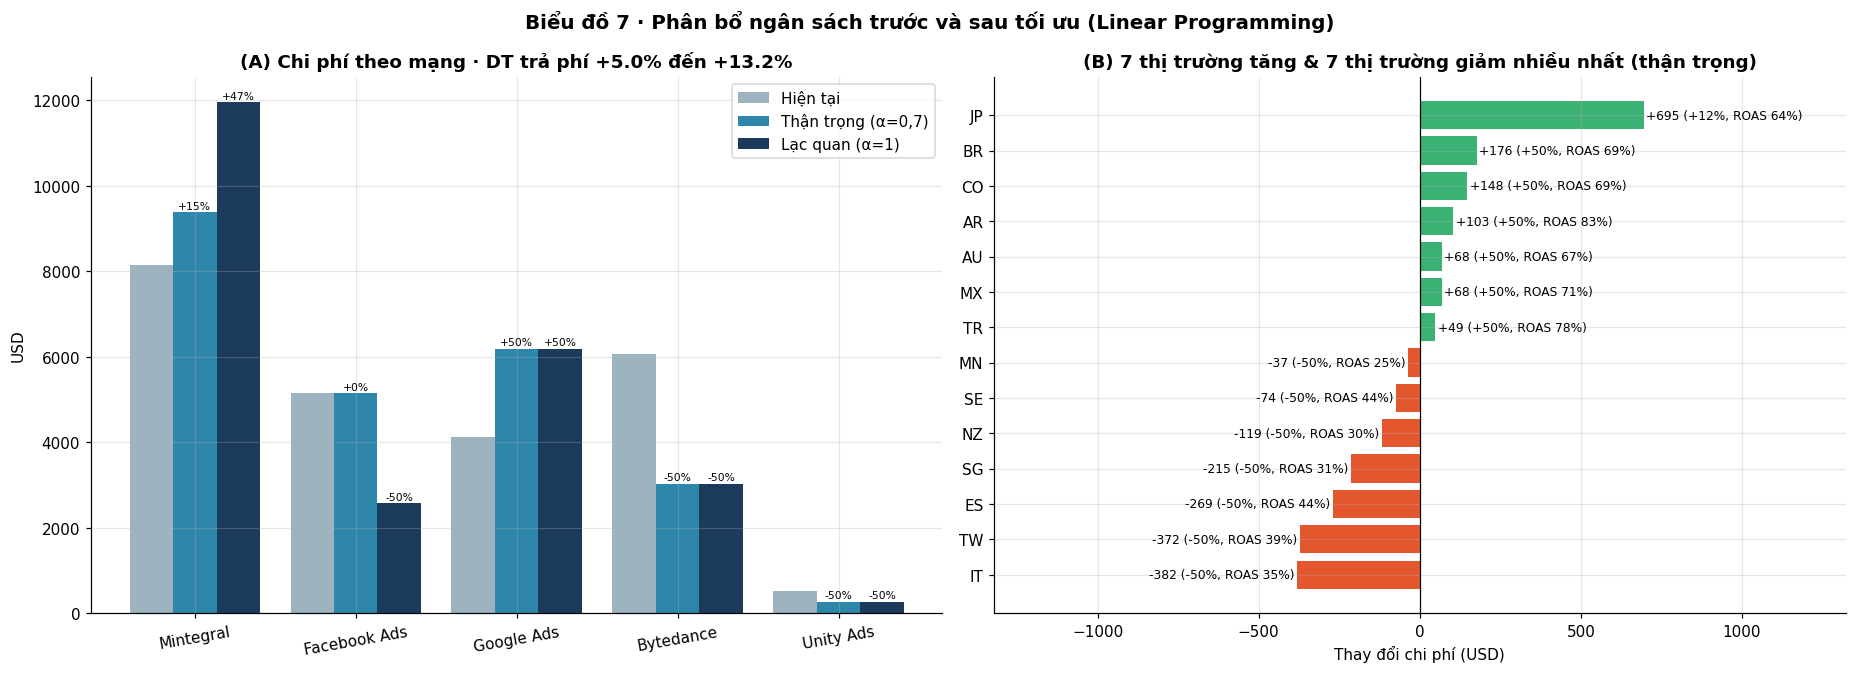

Đã lưu ảnh: outputs\figures\bieu_do_07_phan_bo_ngan_sach_toi_uu.png


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.2))
ax = axes[0]
x = np.arange(len(lp_net)); w = 0.27
for j, (col, lab, colr) in enumerate([('Hiện tại (USD)', 'Hiện tại', C['neutral']), ('Thận trọng (USD)', 'Thận trọng (α=0,7)', C['rev']), ('Lạc quan (USD)', 'Lạc quan (α=1)', C['tier1'])]):
    bars = ax.bar(x + (j - 1) * w, lp_net[col], w, label=lab, color=colr)
    if j > 0:
        dcol = 'Thận trọng Δ%' if j == 1 else 'Lạc quan Δ%'
        for bb, v, dv in zip(bars, lp_net[col], lp_net[dcol]):
            ax.text(bb.get_x() + bb.get_width()/2, v + 80, f'{dv:+.0f}%', ha='center', fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(lp_net['Mạng'], rotation=10); ax.set_ylabel('USD')
ax.set_title(f"(A) Chi phí theo mạng · DT trả phí +{summary_net.loc[2,'Thận trọng']:.1f}% đến +{summary_net.loc[2,'Lạc quan']:.1f}%"); ax.legend()

ax = axes[1]
chg = pd.concat([lp_ctry.nsmallest(7, 'Thận trọng Δ USD'), lp_ctry.nlargest(7, 'Thận trọng Δ USD')]).sort_values('Thận trọng Δ USD')
bars = ax.barh(chg.Code, chg['Thận trọng Δ USD'], color=[C['bad'] if v < 0 else C['good'] for v in chg['Thận trọng Δ USD']])
for bb, (_, r) in zip(bars, chg.iterrows()):
    v = r['Thận trọng Δ USD']
    ax.text(v + (8 if v > 0 else -8), bb.get_y() + bb.get_height()/2, f"{v:+,.0f} ({r['Thận trọng Δ%']:+.0f}%, ROAS {r['ROAS_%']:.0f}%)",
            va='center', ha='left' if v > 0 else 'right', fontsize=8)
lim = chg['Thận trọng Δ USD'].abs().max() * 1.9
ax.set_xlim(-lim, lim); ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Thay đổi chi phí (USD)'); ax.set_title('(B) 7 thị trường tăng & 7 thị trường giảm nhiều nhất (thận trọng)')
fig.suptitle('Biểu đồ 7 · Phân bổ ngân sách trước và sau tối ưu (Linear Programming)', fontsize=13, fontweight='bold')
fig.tight_layout()
save_fig(fig, 'bieu_do_07_phan_bo_ngan_sach_toi_uu')

### Biểu đồ bổ sung 6 · Phân tích độ nhạy của mô hình tối ưu
Kết quả phụ thuộc mạnh vào 2 giả định: α (ROAS phần chi thêm so với hiện tại) và biên độ thay đổi tối đa. Biểu đồ cho thấy **dù nới lỏng giả định, ROAS vẫn không chạm 100%**.

,alpha,Uplift theo mạng %,Uplift theo TT %
0,0.500,1.610,0.896
1,0.550,2.452,1.178
2,0.600,3.295,1.486
3,0.650,4.138,1.868
4,0.700,5.039,2.289
5,0.750,5.947,2.792
6,0.800,7.038,3.459
7,0.850,8.585,4.483
8,0.900,10.132,5.565
9,0.950,11.679,6.750


,max_change,alpha,ROAS trả phí theo mạng %,ROAS theo TT %
0,0.250,0.700,52.601,57.266
1,0.250,1.000,54.701,58.925
2,0.500,0.700,53.893,57.914
3,0.500,1.000,58.094,61.233
4,0.750,0.700,55.186,58.562
5,0.750,1.000,61.487,63.540
6,1.000,0.700,56.479,59.210
7,1.000,1.000,64.880,65.848


Đã lưu bảng: outputs\tables\5_2_do_nhay_alpha.csv
Đã lưu bảng: outputs\tables\5_2_do_nhay_bien_do.csv
• roas_mang_cao_nhat_khi_max_change_100%_alpha_1: 64.8798


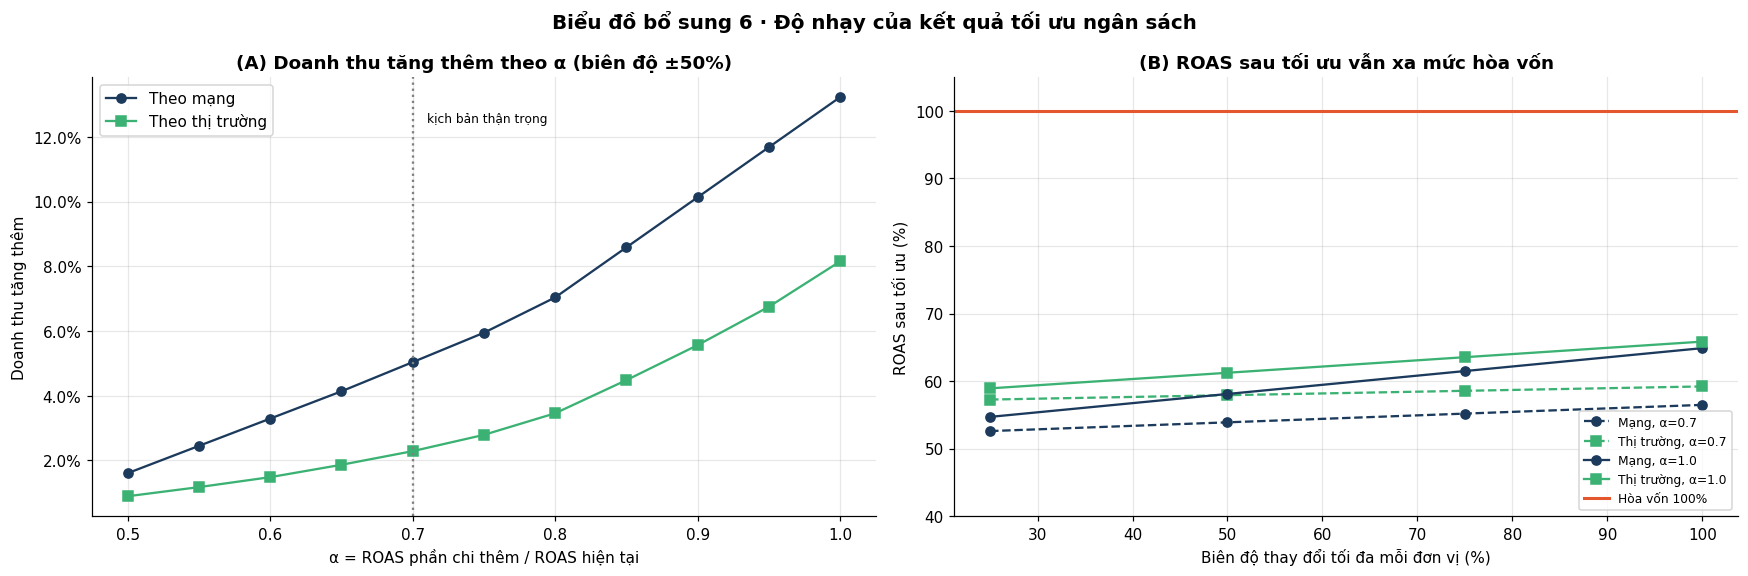

Đã lưu ảnh: outputs\figures\bieu_do_bs_06_do_nhay_toi_uu.png


In [21]:
alphas = np.round(np.arange(0.5, 1.001, 0.05), 2)
sens_a = []
for a in alphas:
    _, rn = optimize_budget(paid.Cost, paid.ROAS, a); _, rc = optimize_budget(cm.Cost, cm.ROAS, a)
    sens_a.append([a, (rn.sum() / PAID_REV - 1) * 100, (rc.sum() / cur_rev_c - 1) * 100])
sens_a = pd.DataFrame(sens_a, columns=['alpha', 'Uplift theo mạng %', 'Uplift theo TT %'])
changes = [0.25, 0.5, 0.75, 1.0]
sens_m = []
for mc in changes:
    for a in [CONSERVATIVE_FACTOR, 1.0]:
        cn, rn = optimize_budget(paid.Cost, paid.ROAS, a, mc); cc_, rc = optimize_budget(cm.Cost, cm.ROAS, a, mc)
        sens_m.append([mc, a, rn.sum() / cn.sum() * 100, rc.sum() / cc_.sum() * 100])
sens_m = pd.DataFrame(sens_m, columns=['max_change', 'alpha', 'ROAS trả phí theo mạng %', 'ROAS theo TT %'])
display(sens_a); display(sens_m)
save_table(sens_a, '5_2_do_nhay_alpha'); save_table(sens_m, '5_2_do_nhay_bien_do')
log('roas_mang_cao_nhat_khi_max_change_100%_alpha_1', sens_m.query('max_change==1.0 and alpha==1.0')['ROAS trả phí theo mạng %'].iloc[0])

fig, axes = plt.subplots(1, 2, figsize=(16, 5.3))
ax = axes[0]
ax.plot(sens_a.alpha, sens_a['Uplift theo mạng %'], marker='o', color=C['tier1'], label='Theo mạng')
ax.plot(sens_a.alpha, sens_a['Uplift theo TT %'], marker='s', color=C['good'], label='Theo thị trường')
ax.axvline(CONSERVATIVE_FACTOR, color='grey', ls=':'); ax.text(CONSERVATIVE_FACTOR + 0.01, ax.get_ylim()[1] * 0.9, 'kịch bản thận trọng', fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlabel('α = ROAS phần chi thêm / ROAS hiện tại')
ax.set_ylabel('Doanh thu tăng thêm'); ax.set_title('(A) Doanh thu tăng thêm theo α (biên độ ±50%)'); ax.legend()
ax = axes[1]
for a, ls in [(CONSERVATIVE_FACTOR, '--'), (1.0, '-')]:
    d = sens_m[sens_m.alpha == a]
    ax.plot(d.max_change * 100, d['ROAS trả phí theo mạng %'], ls=ls, marker='o', color=C['tier1'], label=f'Mạng, α={a}')
    ax.plot(d.max_change * 100, d['ROAS theo TT %'], ls=ls, marker='s', color=C['good'], label=f'Thị trường, α={a}')
ax.axhline(100, color=C['bad'], lw=2, label='Hòa vốn 100%')
ax.set_ylim(40, 105); ax.set_xlabel('Biên độ thay đổi tối đa mỗi đơn vị (%)'); ax.set_ylabel('ROAS sau tối ưu (%)')
ax.set_title('(B) ROAS sau tối ưu vẫn xa mức hòa vốn'); ax.legend(fontsize=8)
fig.suptitle('Biểu đồ bổ sung 6 · Độ nhạy của kết quả tối ưu ngân sách', fontsize=13, fontweight='bold')
fig.tight_layout()
save_fig(fig, 'bieu_do_bs_06_do_nhay_toi_uu')

### Biểu đồ bổ sung 7 · Đường hòa vốn: cần giảm CPI và/hoặc tăng ARPU bao nhiêu?
Chứng minh cho kết luận 5.3: phân bổ lại chỉ là bước nhỏ, phải kết hợp giảm CPI + tăng LTV.

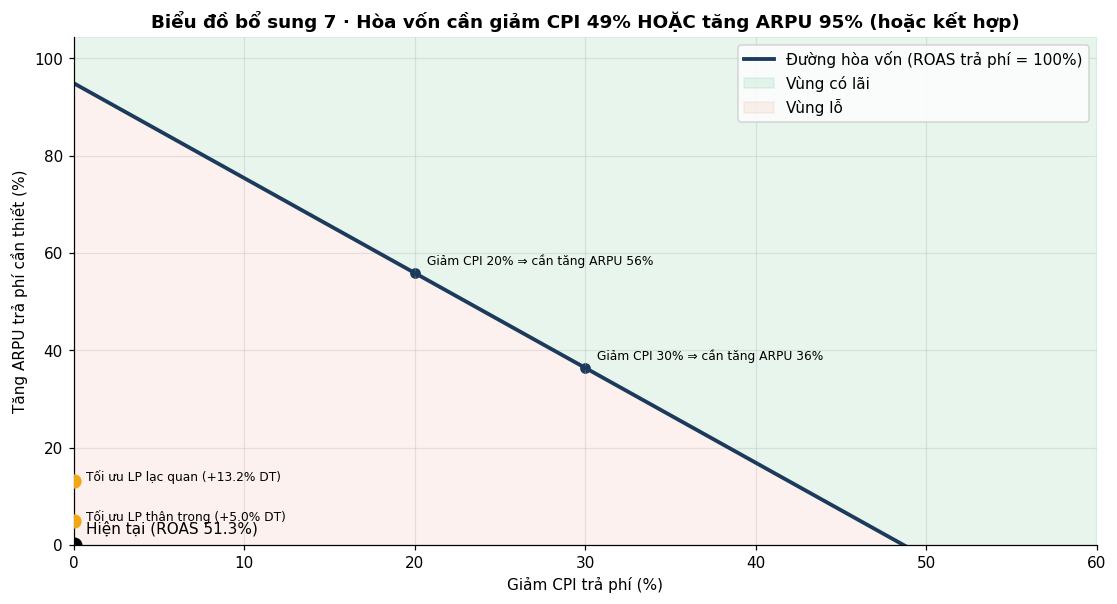

Đã lưu ảnh: outputs\figures\bieu_do_bs_07_duong_hoa_von.png


,Giảm CPI %,Cần tăng ARPU %
0,0.000,94.901
1,10.000,75.411
2,20.000,55.921
3,30.000,36.431
4,40.000,16.941
5,50.000,-2.549
6,60.000,-22.040


Đã lưu bảng: outputs\tables\5_3_duong_hoa_von.csv


In [22]:
cut = np.linspace(0, 0.6, 61)
need_arpu = (PAID_CPI * (1 - cut) / PAID_ARPU - 1) * 100
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(cut * 100, need_arpu, color=C['tier1'], lw=2.5, label='Đường hòa vốn (ROAS trả phí = 100%)')
ax.fill_between(cut * 100, need_arpu, need_arpu.max() * 1.1, color=C['good'], alpha=0.12, label='Vùng có lãi')
ax.fill_between(cut * 100, 0, need_arpu, color=C['bad'], alpha=0.08, label='Vùng lỗ')
uplift_cons = summary_net.loc[2, 'Thận trọng']; uplift_opt = summary_net.loc[2, 'Lạc quan']
ax.scatter([0], [0], s=90, color='black', zorder=5); ax.annotate(f'Hiện tại (ROAS {PAID_ROAS:.1f}%)', (0, 0), xytext=(8, 8), textcoords='offset points')
ax.scatter([0, 0], [uplift_cons, uplift_opt], s=70, color=C['accent'], zorder=5)
ax.annotate(f'Tối ưu LP thận trọng (+{uplift_cons:.1f}% DT)', (0, uplift_cons), xytext=(8, 0), textcoords='offset points', fontsize=8)
ax.annotate(f'Tối ưu LP lạc quan (+{uplift_opt:.1f}% DT)', (0, uplift_opt), xytext=(8, 0), textcoords='offset points', fontsize=8)
for c_ in [0.2, 0.3]:
    a_ = (PAID_CPI * (1 - c_) / PAID_ARPU - 1) * 100
    ax.scatter([c_ * 100], [a_], color=C['tier1']); ax.annotate(f'Giảm CPI {c_*100:.0f}% ⇒ cần tăng ARPU {a_:.0f}%', (c_ * 100, a_), xytext=(8, 5), textcoords='offset points', fontsize=8)
ax.set_xlabel('Giảm CPI trả phí (%)'); ax.set_ylabel('Tăng ARPU trả phí cần thiết (%)')
ax.set_ylim(0, need_arpu.max() * 1.1); ax.set_xlim(0, 60); ax.legend(loc='upper right')
ax.set_title(f'Biểu đồ bổ sung 7 · Hòa vốn cần giảm CPI {(1-PAID_ARPU/PAID_CPI)*100:.0f}% HOẶC tăng ARPU {(PAID_CPI/PAID_ARPU-1)*100:.0f}% (hoặc kết hợp)', fontsize=12)
save_fig(fig, 'bieu_do_bs_07_duong_hoa_von')
be = pd.DataFrame({'Giảm CPI %': cut[::10] * 100, 'Cần tăng ARPU %': need_arpu[::10]})
display(be); save_table(be, '5_3_duong_hoa_von')

## 6. Đề xuất hành động — bảng số liệu cho kế hoạch ngân sách
### 6.1 Kế hoạch theo mạng & 6.2 theo thị trường (từ kịch bản thận trọng)

In [23]:
plan_net = lp_net[['Mạng', 'Hiện tại (USD)', 'ROAS_%', 'Thận trọng (USD)', 'Thận trọng Δ%', 'Lạc quan (USD)', 'Lạc quan Δ%']].copy()
plan_net.loc[len(plan_net)] = ['Tổng', plan_net['Hiện tại (USD)'].sum(), PAID_ROAS, plan_net['Thận trọng (USD)'].sum(), 0,
                               plan_net['Lạc quan (USD)'].sum(), 0]
display(plan_net); save_table(plan_net, '6_1_ke_hoach_ngan_sach_theo_mang')

# Doanh thu dự kiến mất khi cắt 50% Bytedance (guardrail cho thử nghiệm T1)
log('T1_doanh_thu_du_kien_mat_khi_cat_50%_bytedance', 0.5 * b.Cost * b.ROAS / 100)

def act_group(r):
    if r['Hành động (thận trọng)'] == 'Giảm':
        return 'Giảm – nhóm lớn (chi ≥ 100 USD)' if r['Hiện tại (USD)'] >= 100 else 'Giảm – đuôi dài (chi < 100 USD)'
    if r['Hành động (thận trọng)'] == 'Tăng':
        return 'Tăng tối đa 50%' if r['Thận trọng Δ%'] > 49.5 else 'Tăng có điều kiện (một phần)'
    return 'Giữ nguyên & tối ưu'
lp_ctry['Nhóm hành động'] = lp_ctry.apply(act_group, axis=1)
lp_ctry['Revenue'] = cm.Revenue.values; lp_ctry['Profit'] = (cm.Revenue - cm.Cost).values
plan_ctry = lp_ctry.groupby('Nhóm hành động').agg(
    So_TT=('Code', 'count'),
    Thi_truong=('Code', lambda s: ', '.join(lp_ctry.loc[s.index].sort_values('Hiện tại (USD)', ascending=False).Code)),
    Chi_hien_tai=('Hiện tại (USD)', 'sum'), Thay_doi_USD=('Thận trọng Δ USD', 'sum'),
    ROAS_min=('ROAS_%', 'min'), ROAS_max=('ROAS_%', 'max'), Loi_nhuan_hien_tai=('Profit', 'sum'))
plan_ctry['ROAS nhóm %'] = lp_ctry.groupby('Nhóm hành động').apply(lambda d: d.Revenue.sum() / d['Hiện tại (USD)'].sum() * 100)
display(plan_ctry); save_table(plan_ctry, '6_2_ke_hoach_ngan_sach_theo_thi_truong', index=True)
for g_, r in plan_ctry.iterrows():
    log(f'ke_hoach[{g_}]', f'{r.So_TT} TT | Δ {r.Thay_doi_USD:+,.2f} USD | ROAS {r.ROAS_min:.1f}–{r.ROAS_max:.1f}% | {r.Thi_truong[:120]}')

,Mạng,Hiện tại (USD),ROAS_%,Thận trọng (USD),Thận trọng Δ%,Lạc quan (USD),Lạc quan Δ%
0,Mintegral,"8,152.920",61.207,"9,385.535",15.119,"11,957.480",46.665
1,Facebook Ads,"5,143.890",48.088,"5,143.890",0.000,"2,571.945",-50.000
2,Google Ads,"4,128.270",71.892,"6,192.405",50.000,"6,192.405",50.000
3,Bytedance,"6,066.690",27.699,"3,033.345",-50.000,"3,033.345",-50.000
4,Unity Ads,526.810,40.130,263.405,-50.000,263.405,-50.000
5,Tổng,"24,018.580",51.308,"24,018.580",0.000,"24,018.580",0.000


Đã lưu bảng: outputs\tables\6_1_ke_hoach_ngan_sach_theo_mang.csv
• T1_doanh_thu_du_kien_mat_khi_cat_50%_bytedance: 840.21


,So_TT,Thi_truong,Chi_hien_tai,Thay_doi_USD,ROAS_min,ROAS_max,Loi_nhuan_hien_tai,ROAS nhóm %
Nhóm hành động,,,,,,,,
Giảm – nhóm lớn (chi ≥ 100 USD),6,"IT, TW, ES, SG, NZ, SE","2,859.710","-1,429.855",29.674,44.287,"-1,796.530",37.178
Giảm – đuôi dài (chi < 100 USD),29,"MN, CM, TZ, CD, TJ, FI, SO, LA, GA, GN, RU, MG...",556.540,-278.270,11.651,43.445,-399.270,28.259
Giữ nguyên & tối ưu,30,"US, KR, DE, ZA, CZ, CA, VN, ID, CH, UK, FR, PH...","12,409.750",0.000,45.861,63.836,"-5,687.980",54.165
Tăng có điều kiện (một phần),1,JP,"5,836.810",695.355,64.078,64.078,"-2,096.680",64.078
Tăng tối đa 50%,34,"BR, CO, AR, AU, MX, TR, BE, PL, EC, TH, AZ, UY...","2,025.540","1,012.770",66.848,228.571,-296.030,85.385


Đã lưu bảng: outputs\tables\6_2_ke_hoach_ngan_sach_theo_thi_truong.csv
• ke_hoach[Giảm – nhóm lớn (chi ≥ 100 USD)]: 6 TT | Δ -1,429.86 USD | ROAS 29.7–44.3% | IT, TW, ES, SG, NZ, SE
• ke_hoach[Giảm – đuôi dài (chi < 100 USD)]: 29 TT | Δ -278.27 USD | ROAS 11.7–43.4% | MN, CM, TZ, CD, TJ, FI, SO, LA, GA, GN, RU, MG, TG, HT, ZM, LK, MZ, MR, CG, MW, LR, CU, TD, FJ, BJ, SR, NE, GY, ML
• ke_hoach[Giữ nguyên & tối ưu]: 30 TT | Δ +0.00 USD | ROAS 45.9–63.8% | US, KR, DE, ZA, CZ, CA, VN, ID, CH, UK, FR, PH, AT, HK, DK, BO, AM, GE, MY, KE, PY, BW, AL, IN, MK, SN, KZ, GH, PF, SL
• ke_hoach[Tăng có điều kiện (một phần)]: 1 TT | Δ +695.36 USD | ROAS 64.1–64.1% | JP
• ke_hoach[Tăng tối đa 50%]: 34 TT | Δ +1,012.77 USD | ROAS 66.8–228.6% | BR, CO, AR, AU, MX, TR, BE, PL, EC, TH, AZ, UY, VE, PA, BY, MA, CL, GT, HN, PE, PT, MD, TN, MU, BA, RS, RO, TM, CR, DO, 


### Biểu đồ bổ sung 8 · Tổng quan kế hoạch: tiền rút ra từ đâu, đổ vào đâu (theo cụm)

,Hien_tai,Than_trong,Δ USD,Δ %
Cluster,,,,
"Tier 1 – Chi tiêu lớn, đốt tiền","20,140.380","19,459.380",-681.000,-3.381
"Mới nổi – Install lớn, chi phí thấp","2,469.440","3,171.785",702.345,28.441
Ngách ROI cao,579.350,791.075,211.725,36.545
Hiệu quả thấp – Quy mô nhỏ,499.180,266.110,-233.070,-46.691


Đã lưu bảng: outputs\tables\6_2_thay_doi_ngan_sach_theo_cum.csv


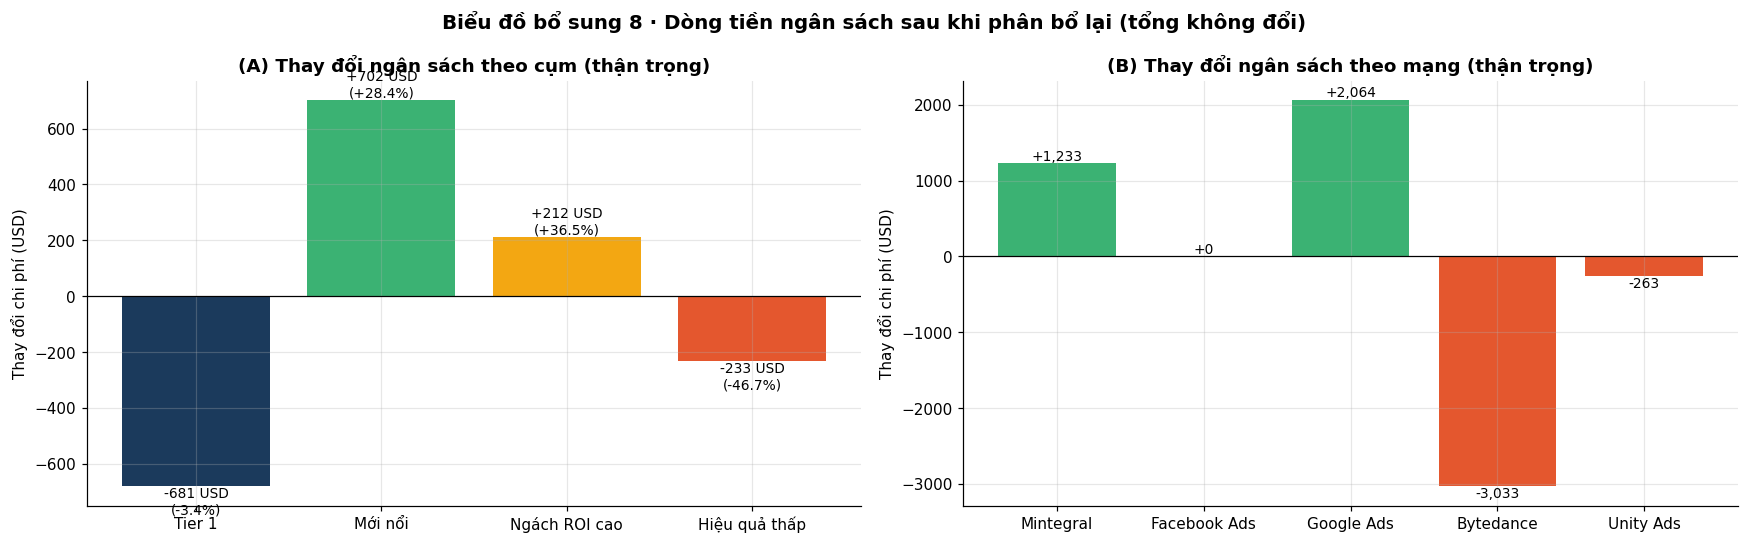

Đã lưu ảnh: outputs\figures\bieu_do_bs_08_dong_tien_ngan_sach.png


In [24]:
by_cl = lp_ctry.groupby('Cluster').agg(Hien_tai=('Hiện tại (USD)', 'sum'), Than_trong=('Thận trọng (USD)', 'sum')).reindex(CL_ORDER)
by_cl['Δ USD'] = by_cl.Than_trong - by_cl.Hien_tai; by_cl['Δ %'] = by_cl['Δ USD'] / by_cl.Hien_tai * 100
display(by_cl); save_table(by_cl, '6_2_thay_doi_ngan_sach_theo_cum', index=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax = axes[0]
bars = ax.bar([c.split(' – ')[0] for c in CL_ORDER], by_cl['Δ USD'], color=[CL_COLORS[c] for c in CL_ORDER])
for bb, v, p_ in zip(bars, by_cl['Δ USD'], by_cl['Δ %']):
    ax.text(bb.get_x() + bb.get_width()/2, v, f'{v:+,.0f} USD\n({p_:+.1f}%)', ha='center', va='bottom' if v >= 0 else 'top', fontsize=9)
ax.axhline(0, color='black', lw=0.8); ax.set_ylabel('Thay đổi chi phí (USD)'); ax.set_title('(A) Thay đổi ngân sách theo cụm (thận trọng)')
ax = axes[1]
pn = plan_net.iloc[:-1]
bars = ax.bar(pn['Mạng'], pn['Thận trọng (USD)'] - pn['Hiện tại (USD)'], color=[C['good'] if v > 0 else C['bad'] if v < 0 else C['neutral'] for v in pn['Thận trọng (USD)'] - pn['Hiện tại (USD)']])
for bb, v in zip(bars, pn['Thận trọng (USD)'] - pn['Hiện tại (USD)']):
    ax.text(bb.get_x() + bb.get_width()/2, v, f'{v:+,.0f}', ha='center', va='bottom' if v >= 0 else 'top', fontsize=9)
ax.axhline(0, color='black', lw=0.8); ax.set_ylabel('Thay đổi chi phí (USD)'); ax.set_title('(B) Thay đổi ngân sách theo mạng (thận trọng)')
fig.suptitle('Biểu đồ bổ sung 8 · Dòng tiền ngân sách sau khi phân bổ lại (tổng không đổi)', fontsize=13, fontweight='bold')
fig.tight_layout()
save_fig(fig, 'bieu_do_bs_08_dong_tien_ngan_sach')

## 7. Phụ lục & xuất toàn bộ kết quả

In [25]:
appendix = ctry.merge(lp_ctry[['Code', 'Thận trọng (USD)', 'Thận trọng Δ%', 'Hành động (thận trọng)']], on='Code', how='left')
appendix = appendix[['Country', 'Install', 'Cost', 'Revenue', 'CPI', 'ARPU', 'ROAS', 'Profit', 'Quadrant', 'Cluster',
                     'Thận trọng (USD)', 'Thận trọng Δ%', 'Hành động (thận trọng)']]
appendix.insert(0, '#', range(1, len(appendix) + 1))
display(appendix)
save_table(appendix, '7_phu_luc_101_thi_truong')

,#,Country,Install,Cost,Revenue,CPI,ARPU,ROAS,Profit,Quadrant,Cluster,Thận trọng (USD),Thận trọng Δ%,Hành động (thận trọng)
0,1,Japan (JP),10685,"5,836.810","3,740.130",0.546,0.350,64.078,"-2,096.680",ROAS cao – Quy mô lớn,"Tier 1 – Chi tiêu lớn, đốt tiền","6,532.165",11.913,Tăng
1,2,United States (US),6454,"3,879.180","2,266.180",0.601,0.351,58.419,"-1,613.000",ROAS cao – Quy mô lớn,"Tier 1 – Chi tiêu lớn, đốt tiền","3,879.180",0.000,Giữ nguyên
2,3,South Korea (KR),4780,"2,749.650","1,389.640",0.575,0.291,50.539,"-1,360.010",ROAS thấp – Quy mô lớn (đốt tiền),"Tier 1 – Chi tiêu lớn, đốt tiền","2,749.650",0.000,Giữ nguyên
3,4,Germany (DE),4837,"1,825.670","1,014.310",0.377,0.210,55.558,-811.360,ROAS thấp – Quy mô lớn (đốt tiền),"Tier 1 – Chi tiêu lớn, đốt tiền","1,825.670",0.000,Giữ nguyên
4,5,Italy (IT),2675,763.970,267.530,0.286,0.100,35.018,-496.440,ROAS thấp – Quy mô lớn (đốt tiền),"Tier 1 – Chi tiêu lớn, đốt tiền",381.985,-50.000,Giảm
5,6,Taiwan (TW),2295,743.690,290.700,0.324,0.127,39.089,-452.990,ROAS thấp – Quy mô lớn (đốt tiền),"Tier 1 – Chi tiêu lớn, đốt tiền",371.845,-50.000,Giảm
6,7,South Africa (ZA),2492,708.540,353.220,0.284,0.142,49.852,-355.320,ROAS thấp – Quy mô lớn (đốt tiền),"Tier 1 – Chi tiêu lớn, đốt tiền",708.540,0.000,Giữ nguyên
7,8,Czechia (CZ),2677,670.360,348.340,0.250,0.130,51.963,-322.020,ROAS thấp – Quy mô lớn (đốt tiền),"Tier 1 – Chi tiêu lớn, đốt tiền",670.360,0.000,Giữ nguyên
8,9,Spain (ES),2942,537.900,238.220,0.183,0.081,44.287,-299.680,ROAS thấp – Quy mô lớn (đốt tiền),"Tier 1 – Chi tiêu lớn, đốt tiền",268.950,-50.000,Giảm
9,10,Canada (CA),1583,450.760,227.540,0.285,0.144,50.479,-223.220,ROAS thấp – Quy mô lớn (đốt tiền),"Tier 1 – Chi tiêu lớn, đốt tiền",450.760,0.000,Giữ nguyên


Đã lưu bảng: outputs\tables\7_phu_luc_101_thi_truong.csv


In [26]:
# ---- Excel gộp mọi bảng ----
try:
    xlsx_path = os.path.join(TAB_DIR, 'tat_ca_bang.xlsx')
    with pd.ExcelWriter(xlsx_path) as w:
        for name, df in TABLES.items():
            df.to_excel(w, sheet_name=name[:31], index=False)
    print('Đã lưu', xlsx_path)
except Exception as e:
    print('Không tạo được Excel (cài openpyxl nếu cần):', e)

# ---- JSON + Markdown tóm tắt ----
with open(os.path.join(OUT_DIR, 'ket_qua_chinh.json'), 'w', encoding='utf-8') as f:
    json.dump(RESULTS, f, ensure_ascii=False, indent=2, default=str)

with open(os.path.join(OUT_DIR, 'tom_tat_ket_qua.md'), 'w', encoding='utf-8') as f:
    f.write('# Tóm tắt kết quả notebook UA\n\n## Con số chính\n')
    for k, v in RESULTS.items():
        f.write(f'- **{k}**: {v}\n')
    f.write('\n## Biểu đồ đã xuất\n')
    for p in FIGURES:
        f.write(f'- {os.path.basename(p)}\n')
    f.write('\n## Bảng đã xuất\n')
    for n in TABLES:
        f.write(f'- {n}.csv\n')
    for title, df in [('Bảng hiệu quả theo mạng', net_table), ('Ma trận 4 góc', quad), ('Kết quả phân cụm', cl_tab),
                      ('LP theo mạng', lp_net), ('LP theo thị trường – tổng hợp', summary_ctry), ('Kế hoạch theo thị trường', plan_ctry)]:
        f.write(f'\n## {title}\n\n')
        f.write(df.round(3).to_csv(sep='|'))

# ---- Nén thành 1 file zip để gửi ----
zip_path = 'outputs_bao_cao_UA.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(OUT_DIR):
        for fn in files:
            fp = os.path.join(root, fn); z.write(fp, os.path.relpath(fp, '.'))
print(f'\nHoàn tất: {len(FIGURES)} biểu đồ, {len(TABLES)} bảng, {len(RESULTS)} con số chính.')
print('Gửi file:', os.path.abspath(zip_path))

Đã lưu outputs\tables\tat_ca_bang.xlsx

Hoàn tất: 15 biểu đồ, 33 bảng, 106 con số chính.
Gửi file: c:\Users\Admin\Desktop\TestSonat7\outputs_bao_cao_UA.zip
